# 02 · Feature engineering and further EDA

**Executed on real inputs on 19 October 2026: 20 code cells, 13 figures, no errors.**

Run notebook 01 first. No classifier is trained here. Outcome plots use January–September 2025 training rows only; October–December is validation and January–March 2026 is the final test.

- **A:** schedule, airline/airports, weekday and cyclic month/clock features.
- **B:** A + origin weather, earlier departure history and scheduled traffic.

Historical simulation: a 20-minute weather buffer, maximum three-hour observation age and 28-day history ending seven days before cutoff. Feed timing and archived schedule availability remain assumptions; aircraft rotation is excluded.

Save one unscaled feature Parquet with shared modelling and final-refit membership flags, and update the same preparation manifest. No extra split datasets. [Teacher-reference methodology](../reports/REFERENCE_EDA_REVIEW.md) · [EDA plan](../EDA_PLAN.md).


In [1]:
from pathlib import Path
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
from datetime import datetime, timezone
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns


def show_table(data, **kwargs):
    print(data.to_string(**kwargs))

def show_plot():
    plt.tight_layout()
    plt.show()

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if (ROOT / 'departure-delay-classification/config/project.json').is_file():
    ROOT = ROOT / 'departure-delay-classification'
if not (ROOT / 'config/project.json').is_file():
    raise FileNotFoundError('Open this notebook inside departure-delay-classification.')
RAW = ROOT / 'data/raw'
CONFIG = json.loads((ROOT / 'config/project.json').read_text())
SEED = CONFIG['sampling']['seed']
ORIGINS = CONFIG['scope']['origin_airports']
WRITE_OUTPUTS = True
WEATHER_BUFFER_MINUTES = 20
WEATHER_MAX_AGE_MINUTES = 180
HISTORY_DAYS = CONFIG['history']['window_days']
HISTORY_LAG_DAYS = CONFIG['history']['lag_days']
HISTORY_PRIOR_STRENGTH = 20  # Fixed pseudo-count, not selected from final-period results.
sns.set_theme(style='whitegrid', context='notebook', palette=['#247BA0', '#E08D3C', '#5C946E'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 40)

clean_path = ROOT / 'data/processed/flights_clean.parquet'
manifest_path = ROOT / 'reports/preparation_manifest.json'
missing = [p.name for p in (clean_path, manifest_path) if not p.is_file()]
if missing:
    raise FileNotFoundError(f"Missing handoff: {', '.join(missing)}. Run the final save cell in notebook 01.")
manifest = json.loads(manifest_path.read_text())
assert 'cleaning' in manifest, 'Missing notebook-01 provenance.'
assert manifest['cleaning']['split_definition'] == CONFIG['split'], 'Rebuild notebook 01 with the current timeline.'
flights = pd.read_parquet(clean_path, engine='pyarrow')
assert flights['flight_id'].is_unique
queries = flights.loc[flights['query_eligible']].copy().reset_index(drop=True)
queries['delayed_departure'] = queries['delayed_departure'].astype('int8')
assert queries['split'].isin(['train', 'validation', 'test']).all()
assert len(queries) > 0
show_table(queries.groupby('split', observed=True).size().to_frame('query_flights'))


            query_flights
split                    
test               219748
train              698670
validation         239747


## 0. Audit weather sources

Verify UTC request metadata and retain the three stations. Collapse identical overlapping payloads. The user approved excluding both versions at eight conflicting station/times across 2025 and 2026, recorded in the configuration. All flights remain; the normal as-of join can use an earlier report within the age limit. Any new conflicting timestamps still stop for review.

Weather timestamps are explicitly nanosecond UTC to match the flight timestamps, including under pandas 3.


In [2]:
WEATHER_COLUMNS = ['station', 'valid', 'tmpf', 'dwpf', 'drct', 'sknt', 'gust', 'vsby', 'p01i',
                   'skyc1', 'skyc2', 'skyc3', 'skyc4', 'skyl1', 'skyl2', 'skyl3', 'skyl4',
                   'wxcodes', 'metar']
weather_paths = sorted((RAW / 'weather/observations/2025').glob('2025_*.csv'))
weather_paths += sorted((RAW / 'weather/observations/2026').glob('2026_0[123]_origins.csv'))
assert len(weather_paths) == 39, 'Expected 36 raw 2025 batches and three Q1-2026 responses.'
weather_parts, weather_source_log = [], []
for path in weather_paths:
    metadata = json.loads(path.with_suffix('.csv.json').read_text())
    assert metadata['request']['params']['tz'] in ['Etc/UTC', 'UTC'], f'Non-UTC source: {path.name}'
    raw = pd.read_csv(path, usecols=WEATHER_COLUMNS, dtype='string', keep_default_na=False)
    raw = raw.loc[raw['station'].str.strip().isin(ORIGINS)].copy()
    for column in WEATHER_COLUMNS:
        raw[column] = raw[column].str.strip()
    raw['weather_source_file'] = path.relative_to(ROOT).as_posix()
    weather_parts.append(raw)
    weather_source_log.append({'source': path.relative_to(ROOT).as_posix(), 'scope_raw_rows': len(raw)})
weather = pd.concat(weather_parts, ignore_index=True)
del weather_parts
weather_raw_rows = len(weather)
weather = weather.drop_duplicates(subset=WEATHER_COLUMNS, keep='first').copy()
exact_weather_duplicates = weather_raw_rows - len(weather)
weather['weather_observed_utc'] = pd.to_datetime(weather['valid'], utc=True, errors='coerce').astype('datetime64[ns, UTC]')
if weather['weather_observed_utc'].isna().any():
    show_table(weather.loc[weather['weather_observed_utc'].isna()].head(10))
    raise ValueError('Unparseable weather times require review before a cutoff join.')
conflict = weather.duplicated(['station', 'weather_observed_utc'], keep=False)
weather_conflicts = (weather.loc[conflict].groupby(['station', 'valid']).size()
                     .rename('reports_removed').reset_index())
approved_conflicts = pd.MultiIndex.from_tuples([tuple(key) for key in CONFIG['weather_quality']['excluded_station_times']])
if not pd.MultiIndex.from_frame(weather_conflicts[['station', 'valid']]).isin(approved_conflicts).all():
    show_table(weather_conflicts)
    raise ValueError('New weather conflicts need review; only explicitly approved timestamps may be excluded.')
show_table(weather_conflicts)
weather = weather.loc[~conflict].copy()  # Exclude both versions; retain every flight in the later join.
assert not weather.duplicated(['station', 'weather_observed_utc']).any()
weather = weather.rename(columns={'station': 'origin'})
show_table(pd.Series({'scope_raw_weather_rows': weather_raw_rows,
                   'identical_overlap_rows_removed': exact_weather_duplicates,
                   'conflicting_station_times_excluded': len(weather_conflicts),
                   'conflicting_report_versions_excluded': int(conflict.sum()),
                   'unique_station_time_reports': len(weather)}).to_frame('count'))


  station             valid  reports_removed
0     ATL  2025-06-14 23:40                2
1     ATL  2026-01-06 08:50                2
2     DFW  2025-05-06 16:50                2
3     DFW  2025-12-23 14:50                2
4     ORD  2025-07-20 09:10                2
5     ORD  2025-11-30 14:20                2
6     ORD  2025-12-28 16:50                2
7     ORD  2026-02-20 08:00                2
                                      count
scope_raw_weather_rows                43910
identical_overlap_rows_removed         4871
conflicting_station_times_excluded        8
conflicting_report_versions_excluded     16
unique_station_time_reports           39023


## 3–5. Parse weather and create variables

Parse source codes before plotting. `M` stays unknown; absent gusts are not automatically zero. Precipitation trace becomes zero plus a trace flag. Invalid negative measurements become missing; negative temperatures remain valid.

Ceiling uses every cloud layer in the METAR body before RMK, with the four structured sky columns as fallback. It is the lowest BKN/OVC/VV height, with separate flags for clear/unknown coverage and missing ceiling heights. Unknown condition codes remain unknown.


In [3]:
import re

weather['precip_trace'] = weather['p01i'].eq('T').astype('float64')
numeric_weather = ['tmpf', 'dwpf', 'drct', 'sknt', 'gust', 'vsby', 'p01i',
                   'skyl1', 'skyl2', 'skyl3', 'skyl4']
nonnegative_weather = ['sknt', 'gust', 'vsby', 'p01i', 'skyl1', 'skyl2', 'skyl3', 'skyl4']
weather_treatment_log = []
for column in numeric_weather:
    original = weather[column]
    values = pd.to_numeric(original.mask(original.isin(['M', 'T', ''])), errors='coerce').astype('float64')
    values = values.where(np.isfinite(values))
    if column == 'p01i':
        values = values.mask(original.eq('T'), 0.0)
    negative = values.lt(0) if column in nonnegative_weather else pd.Series(False, index=weather.index)
    weather_treatment_log.append({'variable': column, 'negative_to_missing': int(negative.sum()),
                                  'capping': False})
    weather[column] = values.mask(negative)
weather['precip_trace'] = weather['precip_trace'].where(weather['p01i'].notna())
coverage = weather[[f'skyc{i}' for i in range(1, 5)]]
heights = weather[[f'skyl{i}' for i in range(1, 5)]].set_axis(coverage.columns, axis=1)
ceiling = coverage.isin(['BKN', 'OVC', 'VV'])
coverage_known = coverage.isin(['CLR', 'SKC', 'FEW', 'SCT', 'BKN', 'OVC', 'VV', 'NSC', 'NCD']).any(axis=1)
ceiling_height_missing = (ceiling & heights.isna()).any(axis=1)
# Read all body layers: the structured source has only four cloud slots.
body = weather['metar'].str.split(r'\s+RMK(?:\s|$)', n=1, regex=True).str[0]
cloud_groups = body.str.findall(r'(?<!\S)(?:FEW|SCT|BKN|OVC|VV)(?:\d{3}|///)(?:CB|TCU)?(?=\s|=|$)')

def parse_body_clouds(groups):
    ceilings = [g for g in groups if g.startswith(('BKN', 'OVC', 'VV'))]
    heights = [int(re.search(r'\d{3}', g).group()) * 100 for g in ceilings if '///' not in g]
    return (min(heights) if heights else np.nan, bool(ceilings),
            any('///' in g for g in ceilings))

parsed_clouds = pd.DataFrame(cloud_groups.map(parse_body_clouds).tolist(),
                            columns=['body_ceiling_ft', 'body_has_ceiling', 'body_height_missing'],
                            index=weather.index)
coverage_known |= cloud_groups.str.len().gt(0) | body.str.contains(r'\b(?:CLR|SKC|NSC|NCD)\b', regex=True)
ceiling_height_missing |= parsed_clouds['body_height_missing']
column_ceiling = heights.where(ceiling).min(axis=1)
weather['ceiling_ft'] = pd.concat([column_ceiling, parsed_clouds['body_ceiling_ft']], axis=1).min(axis=1).mask(ceiling_height_missing)
has_ceiling = ceiling.any(axis=1) | parsed_clouds['body_has_ceiling']
weather['no_ceiling_reported'] = (~has_ceiling).astype(float).where(coverage_known)
weather['cloud_coverage_missing'] = (~coverage_known).astype(float)
weather['ceiling_height_missing'] = ceiling_height_missing.astype(float).where(coverage_known)
assert weather.loc[ceiling_height_missing, 'ceiling_ft'].isna().all()
assert weather.loc[~coverage_known, 'no_ceiling_reported'].isna().all()
conditions = weather['wxcodes']
condition_known = ~conditions.isin(['M', ''])
for name, pattern in {'rain_reported': r'RA|DZ', 'frozen_precip_reported': r'SN|SG|PL|IC|GS|GR',
                       'fog_or_mist_reported': r'FG|BR', 'thunder_reported': r'TS'}.items():
    weather[name] = conditions.str.contains(pattern, regex=True, na=False).astype('float64').where(condition_known)
weather['condition_codes_missing'] = (~condition_known).astype('float64')
weather = weather.rename(columns={'tmpf': 'temperature_f', 'sknt': 'wind_knots',
                                   'gust': 'gust_knots', 'vsby': 'visibility_miles',
                                   'p01i': 'precip_inches'})
WEATHER_FEATURES = ['temperature_f', 'wind_knots', 'gust_knots', 'visibility_miles',
    'precip_inches', 'precip_trace', 'ceiling_ft', 'no_ceiling_reported', 'cloud_coverage_missing',
    'rain_reported', 'frozen_precip_reported', 'fog_or_mist_reported', 'thunder_reported',
    'condition_codes_missing', 'ceiling_height_missing']
show_table(pd.DataFrame(weather_treatment_log))


   variable  negative_to_missing  capping
0      tmpf                    0    False
1      dwpf                    0    False
2      drct                    0    False
3      sknt                    0    False
4      gust                    0    False
5      vsby                    0    False
6      p01i                    0    False
7     skyl1                    0    False
8     skyl2                    0    False
9     skyl3                    0    False
10    skyl4                    0    False


## 1. Weather univariate analysis

Inspect units, distributions, station differences and missingness in training-period reports. Report counts differ from the joined-flight counts used later.


                           count          mean          std     min      1%     50%       95%       99%       max  missing_fraction
temperature_f            22909.0     63.493457    19.576696   -8.00   13.00    69.0     89.00     94.00    102.00          0.000044
wind_knots               22908.0      8.227431     4.566383    0.00    0.00     8.0     16.65     22.00     45.00          0.000087
gust_knots                4195.0     23.209535     5.856877   13.00   14.00    22.0     34.00     41.00     78.00          0.816892
visibility_miles         22910.0      9.125948     2.221741    0.12    0.75    10.0     10.00     10.00     10.00          0.000000
precip_inches            22904.0      0.007612     0.055848    0.00    0.00     0.0      0.02      0.19      1.68          0.000262
precip_trace             22904.0      0.079200     0.270057    0.00    0.00     0.0      1.00      1.00      1.00          0.000262
ceiling_ft               13384.0  10320.808279  9528.565712  100.00  200.00 

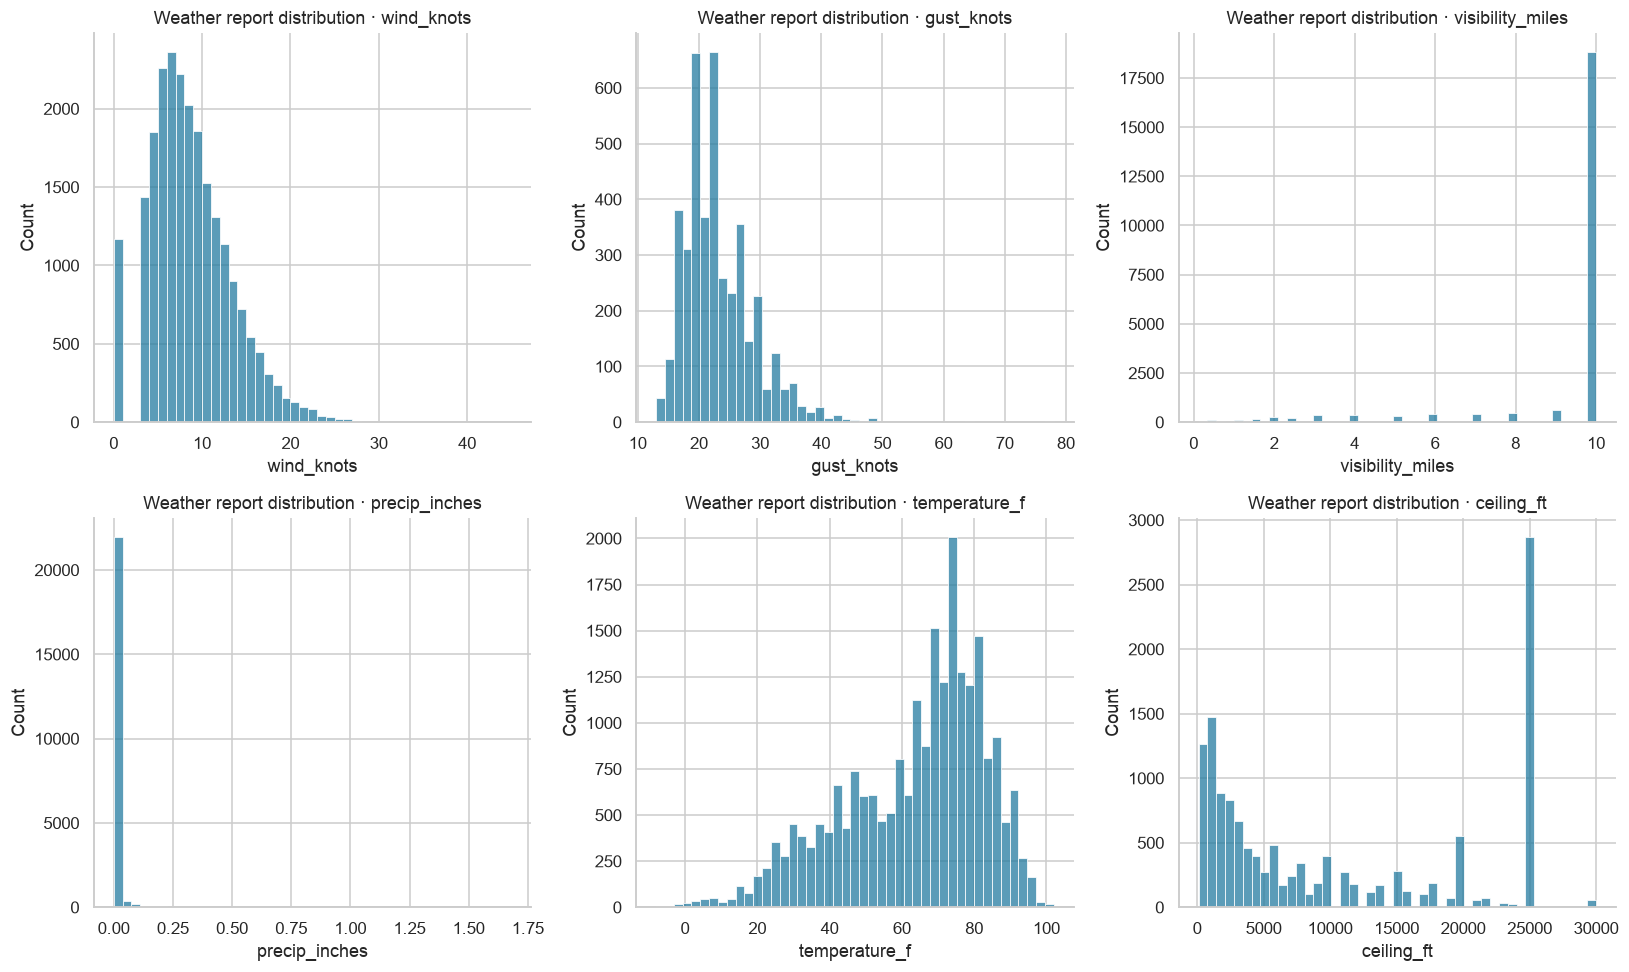

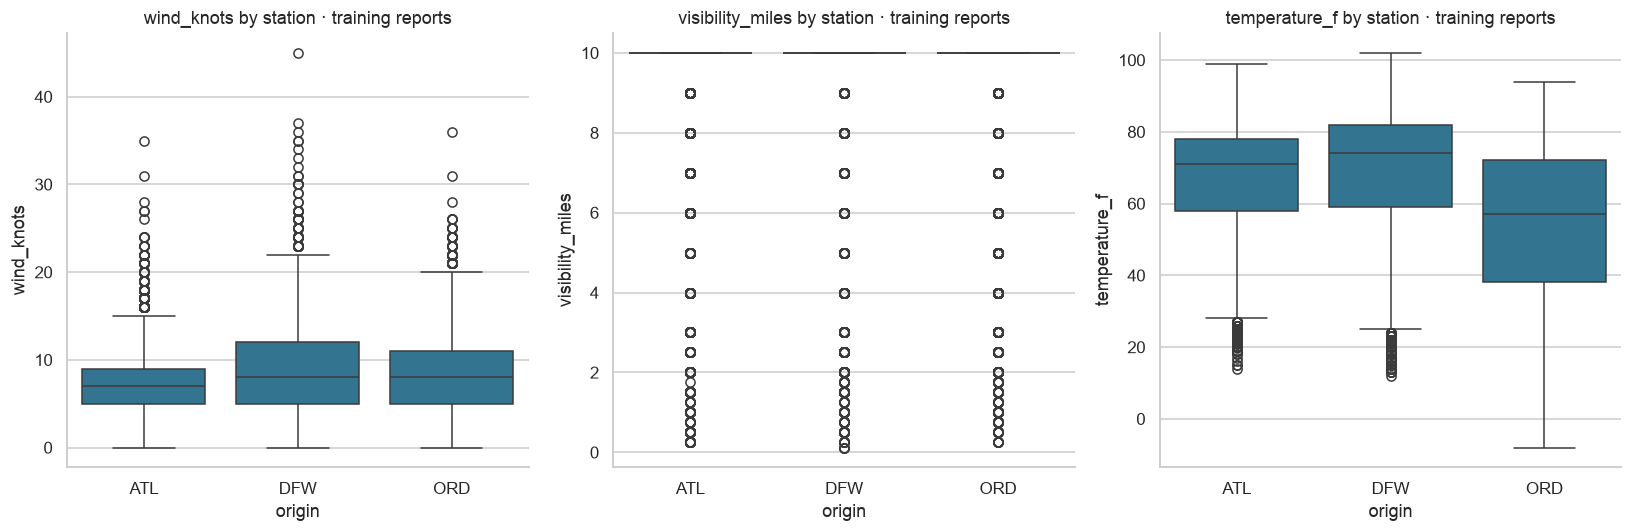

In [4]:
weather_train = weather.loc[weather['weather_observed_utc'].between(
    pd.Timestamp(CONFIG['split']['train_start'], tz='UTC'),
    pd.Timestamp(CONFIG['split']['train_end'], tz='UTC') + pd.Timedelta(days=1), inclusive='left')].copy()
weather_summary = weather_train[WEATHER_FEATURES].describe(percentiles=[.01, .5, .95, .99]).T
weather_summary['missing_fraction'] = weather_train[WEATHER_FEATURES].isna().mean()
show_table(weather_summary)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for column, ax in zip(['wind_knots', 'gust_knots', 'visibility_miles', 'precip_inches', 'temperature_f', 'ceiling_ft'], axes.flat):
    sns.histplot(data=weather_train, x=column, bins=45, ax=ax)
    ax.set_title(f'Weather report distribution · {column}')
show_plot()

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for column, ax in zip(['wind_knots', 'visibility_miles', 'temperature_f'], axes):
    sns.boxplot(data=weather_train, x='origin', y=column, showfliers=True, ax=ax)
    ax.set_title(f'{column} by station · training reports')
show_plot()


### Types, cardinality and skewness

Distinguish continuous measurements from binary flags. Summarize measurement skewness; describe flags through their frequencies and missingness.


In [5]:
weather_profile = pd.DataFrame({'dtype': weather_train[WEATHER_FEATURES].dtypes.astype(str),
                                'unique_nonmissing': weather_train[WEATHER_FEATURES].nunique(),
                                'missing_percent': weather_train[WEATHER_FEATURES].isna().mean().mul(100)})
continuous_weather = ['temperature_f', 'wind_knots', 'gust_knots', 'visibility_miles', 'precip_inches', 'ceiling_ft']
weather_profile['role'] = ['continuous measurement' if c in continuous_weather else 'binary indicator'
                           for c in weather_profile.index]
show_table(weather_profile)
print('\nContinuous weather: mean, median, range and skewness')
show_table(weather_train[continuous_weather].agg(['count', 'mean', 'median', 'min', 'max', 'skew']).T)


                           dtype  unique_nonmissing  missing_percent                    role
temperature_f            float64                144         0.004365  continuous measurement
wind_knots               float64                 40         0.008730  continuous measurement
gust_knots               float64                 43        81.689219  continuous measurement
visibility_miles         float64                 18         0.000000  continuous measurement
precip_inches            float64                 90         0.026189  continuous measurement
precip_trace             float64                  2         0.026189        binary indicator
ceiling_ft               float64                 78        41.580096  continuous measurement
no_ceiling_reported      float64                  2         0.008730        binary indicator
cloud_coverage_missing   float64                  2         0.000000        binary indicator
rain_reported            float64                  2        84.255784  

## Match weather to the cutoff

Select the latest observation ≤cutoff−20 minutes, with age ≤180 minutes at cutoff. The lookup tolerance is therefore 160 minutes. Unmatched flights remain in A/B.


             n  missing_reports  median_age_minutes  matched_fraction
origin                                                               
ATL     231994                0                48.0               1.0
DFW     230516                0                47.0               1.0
ORD     236160                0                54.0               1.0


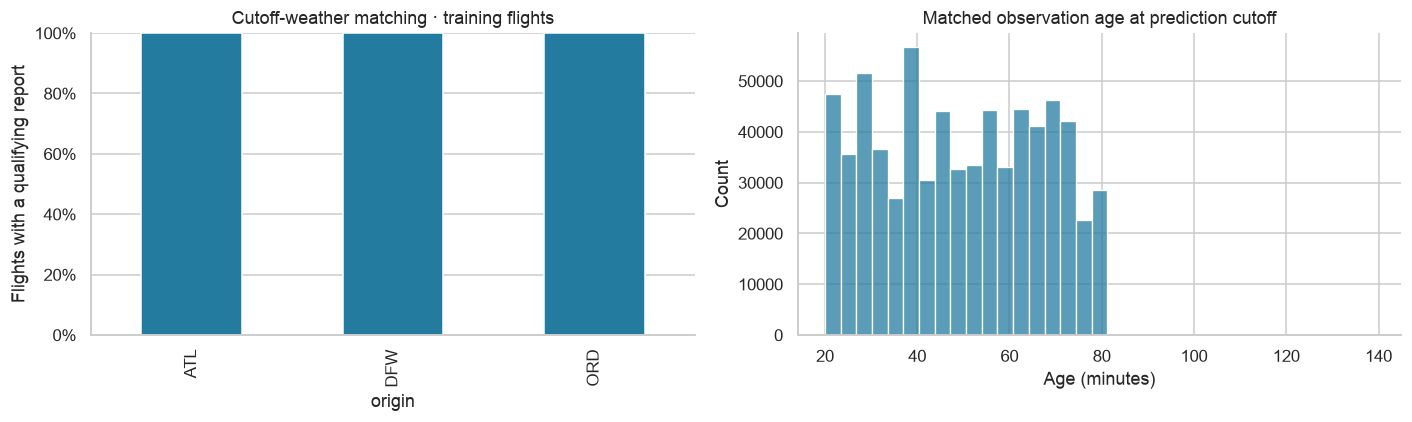

In [6]:
assert 0 <= WEATHER_BUFFER_MINUTES < WEATHER_MAX_AGE_MINUTES
queries['origin'] = queries['origin'].astype('string')
weather['origin'] = weather['origin'].astype('string')
queries['_query_order'] = np.arange(len(queries))
queries['weather_lookup_utc'] = queries['prediction_cutoff_utc'] - pd.Timedelta(minutes=WEATHER_BUFFER_MINUTES)
right_columns = ['origin', 'weather_observed_utc', 'weather_source_file', *WEATHER_FEATURES]
features = pd.merge_asof(
    queries.sort_values('weather_lookup_utc'),
    weather[right_columns].sort_values('weather_observed_utc'),
    left_on='weather_lookup_utc', right_on='weather_observed_utc', by='origin',
    direction='backward', allow_exact_matches=True,
    tolerance=pd.Timedelta(minutes=WEATHER_MAX_AGE_MINUTES - WEATHER_BUFFER_MINUTES),
).sort_values('_query_order').drop(columns='_query_order').reset_index(drop=True)
features['weather_age_minutes'] = (features['prediction_cutoff_utc'] - features['weather_observed_utc']).dt.total_seconds() / 60
features['weather_report_missing'] = features['weather_observed_utc'].isna().astype('int8')
matched = features['weather_observed_utc'].notna()
assert len(features) == len(queries) and features['flight_id'].equals(queries['flight_id'])
assert features.loc[matched, 'weather_age_minutes'].between(WEATHER_BUFFER_MINUTES, WEATHER_MAX_AGE_MINUTES).all()

train_features = features.loc[features['split'].eq('train')].copy()
coverage = train_features.groupby('origin', observed=True).agg(
    n=('flight_id', 'size'), missing_reports=('weather_report_missing', 'sum'),
    median_age_minutes=('weather_age_minutes', 'median'))
coverage['matched_fraction'] = 1 - coverage['missing_reports'] / coverage['n']
show_table(coverage)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
coverage['matched_fraction'].plot.bar(ax=axes[0], ylim=(0, 1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title='Cutoff-weather matching · training flights', ylabel='Flights with a qualifying report')
sns.histplot(data=train_features, x='weather_age_minutes', bins=35, ax=axes[1])
axes[1].set(title='Matched observation age at prediction cutoff', xlabel='Age (minutes)')
show_plot()


## 2. Weather bivariate analysis

Use cutoff-matched inputs for class-conditioned distributions, scatter plots and delay rates. Show unknown conditions explicitly and include group counts.


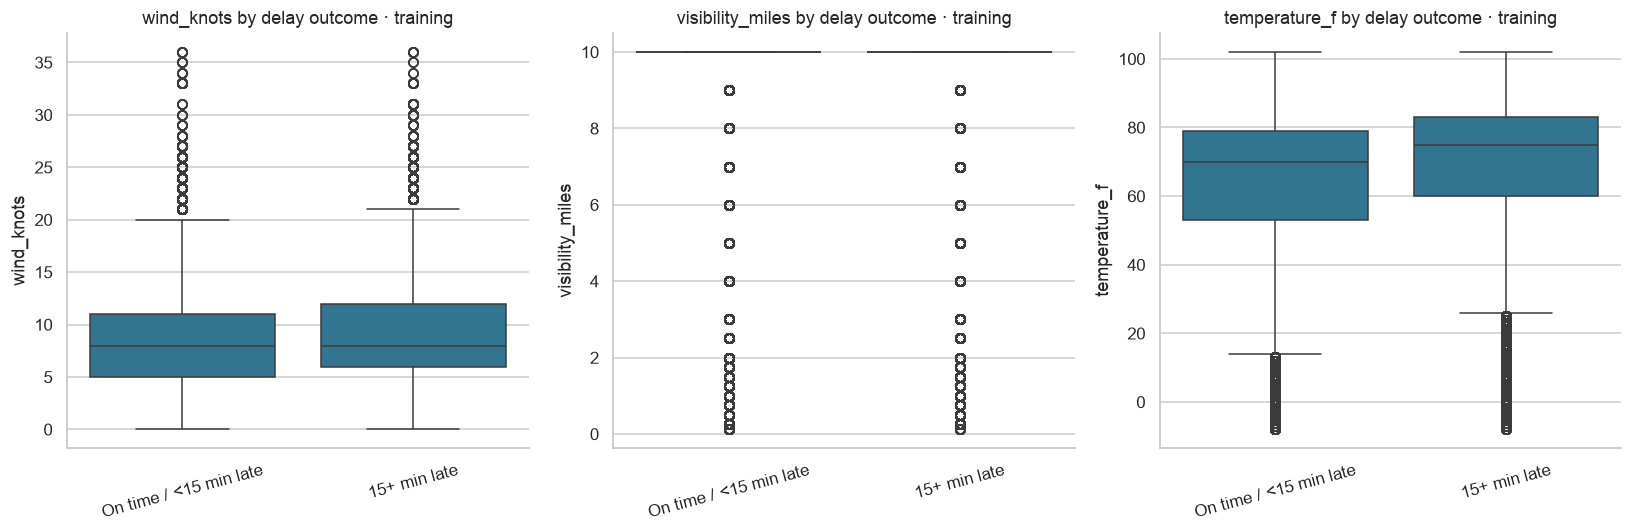

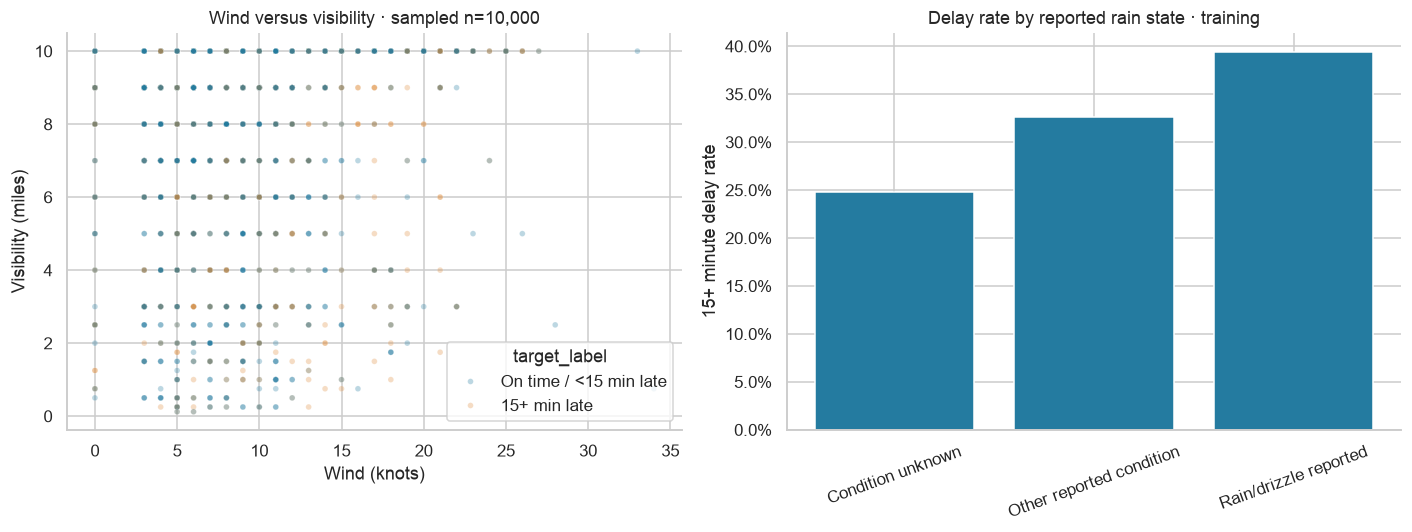

                               n  delayed  delay_rate
rain_state                                           
Condition unknown         632918   156618    0.247454
Other reported condition   29494     9625    0.326338
Rain/drizzle reported      36258    14284    0.393954


In [7]:
train_features['target_label'] = train_features['delayed_departure'].map({0: 'On time / <15 min late', 1: '15+ min late'})
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for column, ax in zip(['wind_knots', 'visibility_miles', 'temperature_f'], axes):
    sns.boxplot(data=train_features, x='target_label', y=column, ax=ax, showfliers=True)
    ax.set(title=f'{column} by delay outcome · training', xlabel='')
    ax.tick_params(axis='x', rotation=15)
show_plot()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
scatter = train_features.sample(n=min(10_000, len(train_features)), random_state=SEED)
sns.scatterplot(data=scatter, x='wind_knots', y='visibility_miles', hue='target_label',
                alpha=.3, s=14, ax=axes[0])
axes[0].set(title=f'Wind versus visibility · sampled n={len(scatter):,}', xlabel='Wind (knots)', ylabel='Visibility (miles)')
condition_view = train_features.assign(rain_state=train_features['rain_reported'].map({0.: 'Other reported condition', 1.: 'Rain/drizzle reported'}).fillna('Condition unknown'))
rain_rates = condition_view.groupby('rain_state', observed=True)['delayed_departure'].agg(n='size', delayed='sum')
rain_rates['delay_rate'] = rain_rates['delayed'] / rain_rates['n']
axes[1].bar(rain_rates.index, rain_rates['delay_rate'])
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Delay rate by reported rain state · training', ylabel='15+ minute delay rate')
show_plot()
show_table(rain_rates)


## 3–4. Missingness and outlier decisions

Separate unmatched reports from missing fields within reports. Keep query rows and valid extremes; fit imputation on training only.


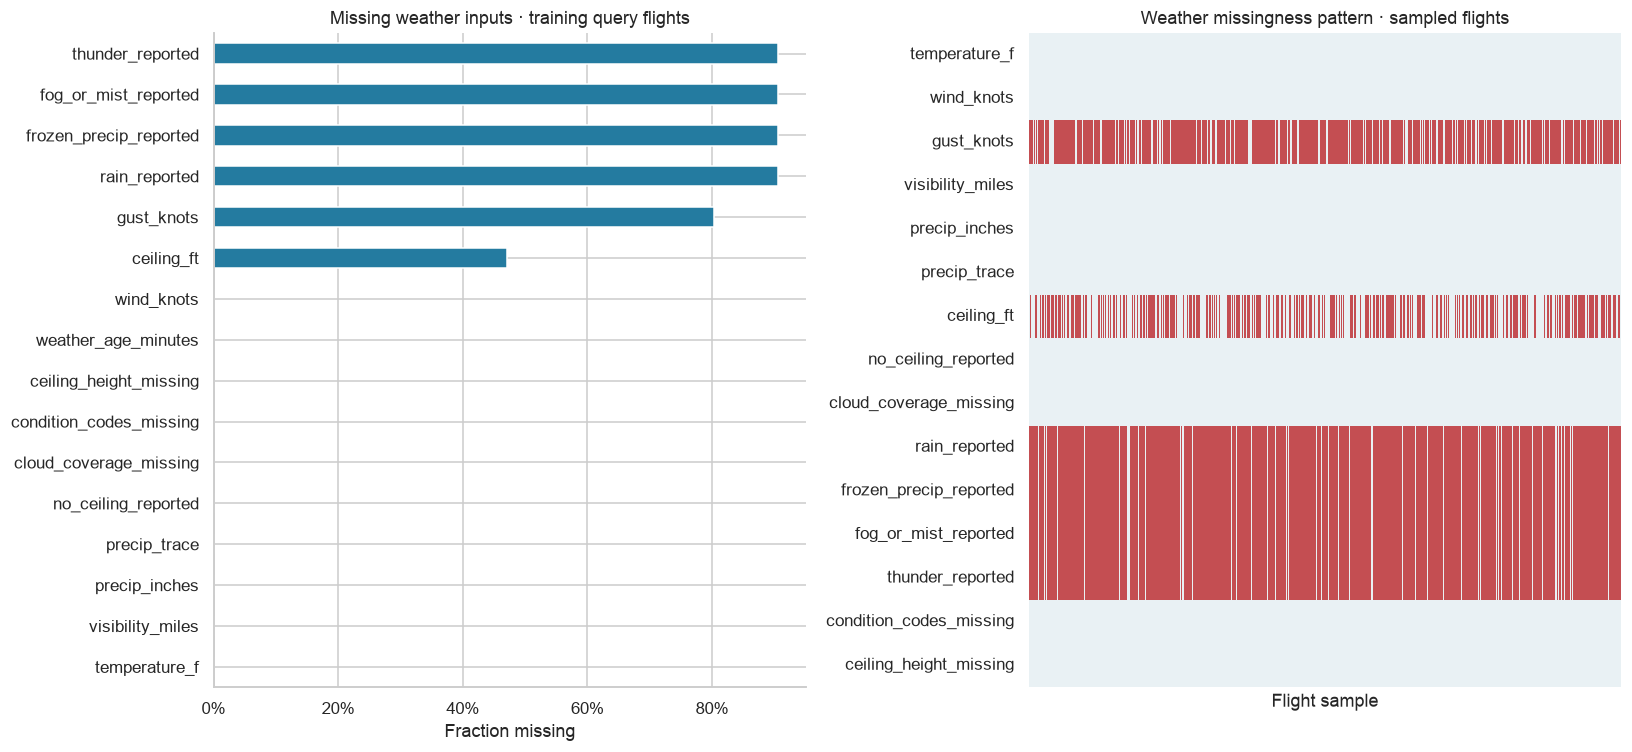

                         missing_fraction
temperature_f                    0.000000
visibility_miles                 0.000000
precip_inches                    0.000000
precip_trace                     0.000000
no_ceiling_reported              0.000000
cloud_coverage_missing           0.000000
condition_codes_missing          0.000000
ceiling_height_missing           0.000000
weather_age_minutes              0.000000
wind_knots                       0.000228
ceiling_ft                       0.471585
gust_knots                       0.802808
rain_reported                    0.905890
frozen_precip_reported           0.905890
fog_or_mist_reported             0.905890
thunder_reported                 0.905890


In [8]:
weather_missing = train_features[[*WEATHER_FEATURES, 'weather_age_minutes']].isna().mean().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
weather_missing.plot.barh(ax=axes[0])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title='Missing weather inputs · training query flights', xlabel='Fraction missing')
missing_plot = train_features.sample(n=min(1_000, len(train_features)), random_state=SEED)
sns.heatmap(missing_plot[WEATHER_FEATURES].isna().T, cbar=False, xticklabels=False,
            cmap=['#E9F1F4', '#C44E52'], ax=axes[1])
axes[1].set(title='Weather missingness pattern · sampled flights', xlabel='Flight sample')
show_plot()
show_table(weather_missing.rename('missing_fraction').to_frame())


### Compare outlier diagnostics

Compare IQR, ±3 SD and upper-99th-percentile flags on training inputs. Zero-heavy precipitation can have IQR=0 without positive amounts being errors. No statistical capping is applied.


In [9]:
def compare_outlier_rules(frame, columns):
    """Report training-only flags without changing the data."""
    rows = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors='coerce').dropna()
        values = values[np.isfinite(values)]
        if values.empty:
            rows.append([column, 0, 'Unavailable: no finite values', *([np.nan] * 4)])
            continue
        q1, q3 = values.quantile([.25, .75])
        iqr, mean, sd = q3 - q1, values.mean(), values.std(ddof=0)
        rules = [('IQR: Q1-1.5IQR to Q3+1.5IQR', q1 - 1.5 * iqr, q3 + 1.5 * iqr),
                 ('Mean +/- 3 SD (ddof=0)', mean - 3 * sd, mean + 3 * sd),
                 ('Above 99th percentile only', -np.inf, values.quantile(.99))]
        for method, lower, upper in rules:
            flagged = (values < lower) | (values > upper)
            rows.append([column, len(values), method, lower if np.isfinite(lower) else np.nan,
                         upper, int(flagged.sum()), 100 * flagged.mean()])
    fields = ['variable', 'n', 'method', 'lower_bound', 'upper_bound', 'flagged_n', 'flagged_percent']
    return pd.DataFrame(rows, columns=fields) if rows else pd.DataFrame()


In [10]:
weather_outlier_review = compare_outlier_rules(train_features,
    ['wind_knots', 'gust_knots', 'visibility_miles', 'precip_inches', 'ceiling_ft'])
show_table(weather_outlier_review, index=False)
print('Diagnostic bounds only. Valid extremes and all eligible query flights remain.')


        variable      n                      method   lower_bound  upper_bound  flagged_n  flagged_percent
      wind_knots 698511 IQR: Q1-1.5IQR to Q3+1.5IQR     -4.000000    20.000000       8455         1.210432
      wind_knots 698511      Mean +/- 3 SD (ddof=0)     -5.012269    21.684110       5673         0.812156
      wind_knots 698511  Above 99th percentile only           NaN    21.000000       5673         0.812156
      gust_knots 137772 IQR: Q1-1.5IQR to Q3+1.5IQR     10.000000    34.000000       4342         3.151584
      gust_knots 137772      Mean +/- 3 SD (ddof=0)      6.474045    38.446113       1163         0.844148
      gust_knots 137772  Above 99th percentile only           NaN    38.000000       1163         0.844148
visibility_miles 698670 IQR: Q1-1.5IQR to Q3+1.5IQR     10.000000    10.000000      86119        12.326134
visibility_miles 698670      Mean +/- 3 SD (ddof=0)      4.460518    14.507537      27960         4.001889
visibility_miles 698670  Above 99th p

### Create a grouping, then compare the target

Adapt the reference's presence-indicator example to zero/trace/positive/unknown precipitation. For a binary target, the group mean is the delay rate. This grouping is EDA-only.


                               n  delay_rate  percent_of_training_queries
precip_state                                                             
Positive amount reported   28097    0.443072                     4.021498
Trace reported             39365    0.359761                     5.634277
Zero amount reported      631208    0.243844                    90.344225


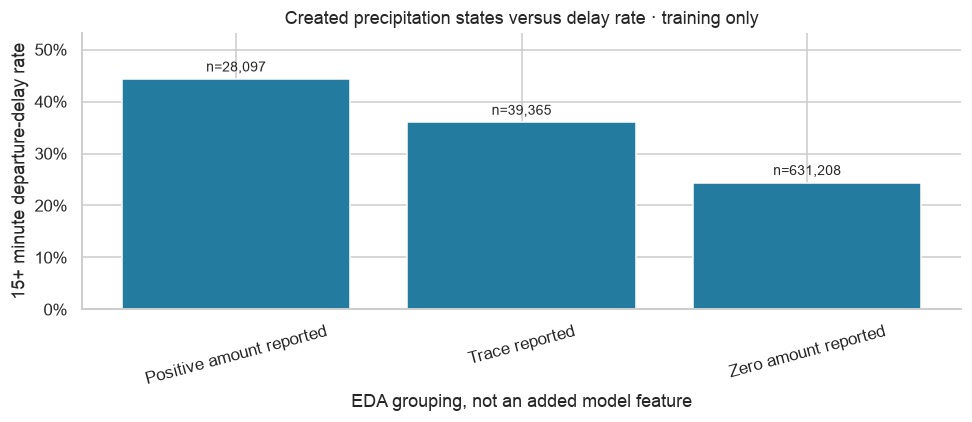

In [11]:
precip_example = train_features[['precip_inches', 'precip_trace', 'delayed_departure']].copy()
precip_example['precip_state'] = np.select(
    [precip_example['precip_trace'].eq(1), precip_example['precip_inches'].gt(0),
     precip_example['precip_inches'].eq(0)],
    ['Trace reported', 'Positive amount reported', 'Zero amount reported'], default='Unknown')
precip_groups = precip_example.groupby('precip_state', observed=True).agg(
    n=('delayed_departure', 'size'), delay_rate=('delayed_departure', 'mean'))
precip_groups['percent_of_training_queries'] = precip_groups['n'] / len(precip_example) * 100
show_table(precip_groups)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(precip_groups.index, precip_groups['delay_rate'])
for i, (_, row) in enumerate(precip_groups.iterrows()):
    ax.annotate(f'n={int(row["n"]):,}', (i, row['delay_rate']),
                xytext=(0, 5), textcoords='offset points', ha='center', fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Created precipitation states versus delay rate · training only',
       ylabel='15+ minute departure-delay rate', xlabel='EDA grouping, not an added model feature')
ax.tick_params(axis='x', rotation=15)
ax.margins(y=.2)
show_plot()


## 5. Earlier departure-history features

Compute origin, airline/origin and route rates using outcome events in **[cutoff−35 days, cutoff−7 days)**. Events are reconstructed from scheduled UTC plus delay. Timely outcome delivery is assumed.

Shrink subgroup rates toward the same past-window origin rate with a fixed prior strength of 20. Retain support/missing-history flags; do not use whole-year prevalence.


In [12]:
events = flights.loc[flights['label_eligible'],
    ['origin', 'airline', 'destination', 'departure_outcome_event_utc', 'delayed_departure']].copy()
assert events['departure_outcome_event_utc'].notna().all()
events['delayed_departure'] = events['delayed_departure'].astype('int8')
history_end = features['prediction_cutoff_utc'] - pd.Timedelta(days=HISTORY_LAG_DAYS)
history_start = history_end - pd.Timedelta(days=HISTORY_DAYS)

def historical_window_counts(query_frame, event_frame, group_columns):
    counts = np.zeros(len(query_frame), dtype=np.int32)
    positives = np.zeros(len(query_frame), dtype=np.int32)
    latest = np.full(len(query_frame), np.iinfo('int64').min, dtype='int64')
    query_groups = query_frame.groupby(group_columns, observed=True, dropna=False).indices
    event_groups = event_frame.groupby(group_columns, observed=True, dropna=False).indices
    lower = history_start.array.asi8
    upper = history_end.array.asi8
    for key, positions in query_groups.items():
        event_positions = event_groups.get(key)
        if event_positions is None:
            continue
        block = event_frame.iloc[event_positions].sort_values('departure_outcome_event_utc')
        times = block['departure_outcome_event_utc'].array.asi8
        cumulative = np.r_[0, block['delayed_departure'].to_numpy(dtype='int64').cumsum()]
        left = np.searchsorted(times, lower[positions], side='left')
        right = np.searchsorted(times, upper[positions], side='left')
        counts[positions] = right - left
        positives[positions] = cumulative[right] - cumulative[left]
        has_history = right > left
        latest[positions[has_history]] = times[right[has_history] - 1]
    return counts, positives, pd.to_datetime(latest, utc=True)

history_definitions = [('history_origin', ['origin']),
                       ('history_airline_origin', ['origin', 'airline']),
                       ('history_route', ['origin', 'destination'])]
for prefix, group_columns in history_definitions:
    n, positives, latest = historical_window_counts(features, events, group_columns)
    features[prefix + '_n'] = n
    raw_rate = np.divide(positives, n, out=np.full(len(features), np.nan), where=n > 0)
    if prefix == 'history_origin':
        features[prefix + '_rate'] = raw_rate
    else:
        prior = features['history_origin_rate'].to_numpy()
        features[prefix + '_rate'] = (positives + HISTORY_PRIOR_STRENGTH * prior) / (n + HISTORY_PRIOR_STRENGTH)
    features[prefix + '_no_history'] = (n == 0).astype('int8')
    features[prefix + '_latest_event_utc'] = latest
    known = n > 0
    assert (features.loc[known, prefix + '_latest_event_utc'] < history_end.loc[known]).all()
    assert (features.loc[known, prefix + '_latest_event_utc'] >= history_start.loc[known]).all()
    assert features[prefix + '_rate'].dropna().between(0, 1).all()


### Scheduled traffic

Count origin schedules in **[scheduled departure−60 minutes, scheduled departure)**, including later-cancelled schedules. The current departure instant is excluded; no actual future traffic is used.


In [13]:
traffic = np.zeros(len(features), dtype=np.int32)
for origin in ORIGINS:
    positions = np.flatnonzero(features['origin'].eq(origin).to_numpy())
    scheduled_times = flights.loc[flights['origin'].eq(origin), 'scheduled_departure_utc'].sort_values().array.asi8
    query_times = features.loc[positions, 'scheduled_departure_utc'].array.asi8
    earlier = query_times - pd.Timedelta(minutes=60).value
    traffic[positions] = np.searchsorted(scheduled_times, query_times, side='left') - np.searchsorted(scheduled_times, earlier, side='left')
features['airport_scheduled_departures_prior_60m'] = traffic
assert (traffic >= 0).all()


## 1–2. History/traffic distributions and relationships

Use training queries. Interpret historical rates alongside support counts and missing-history flags.


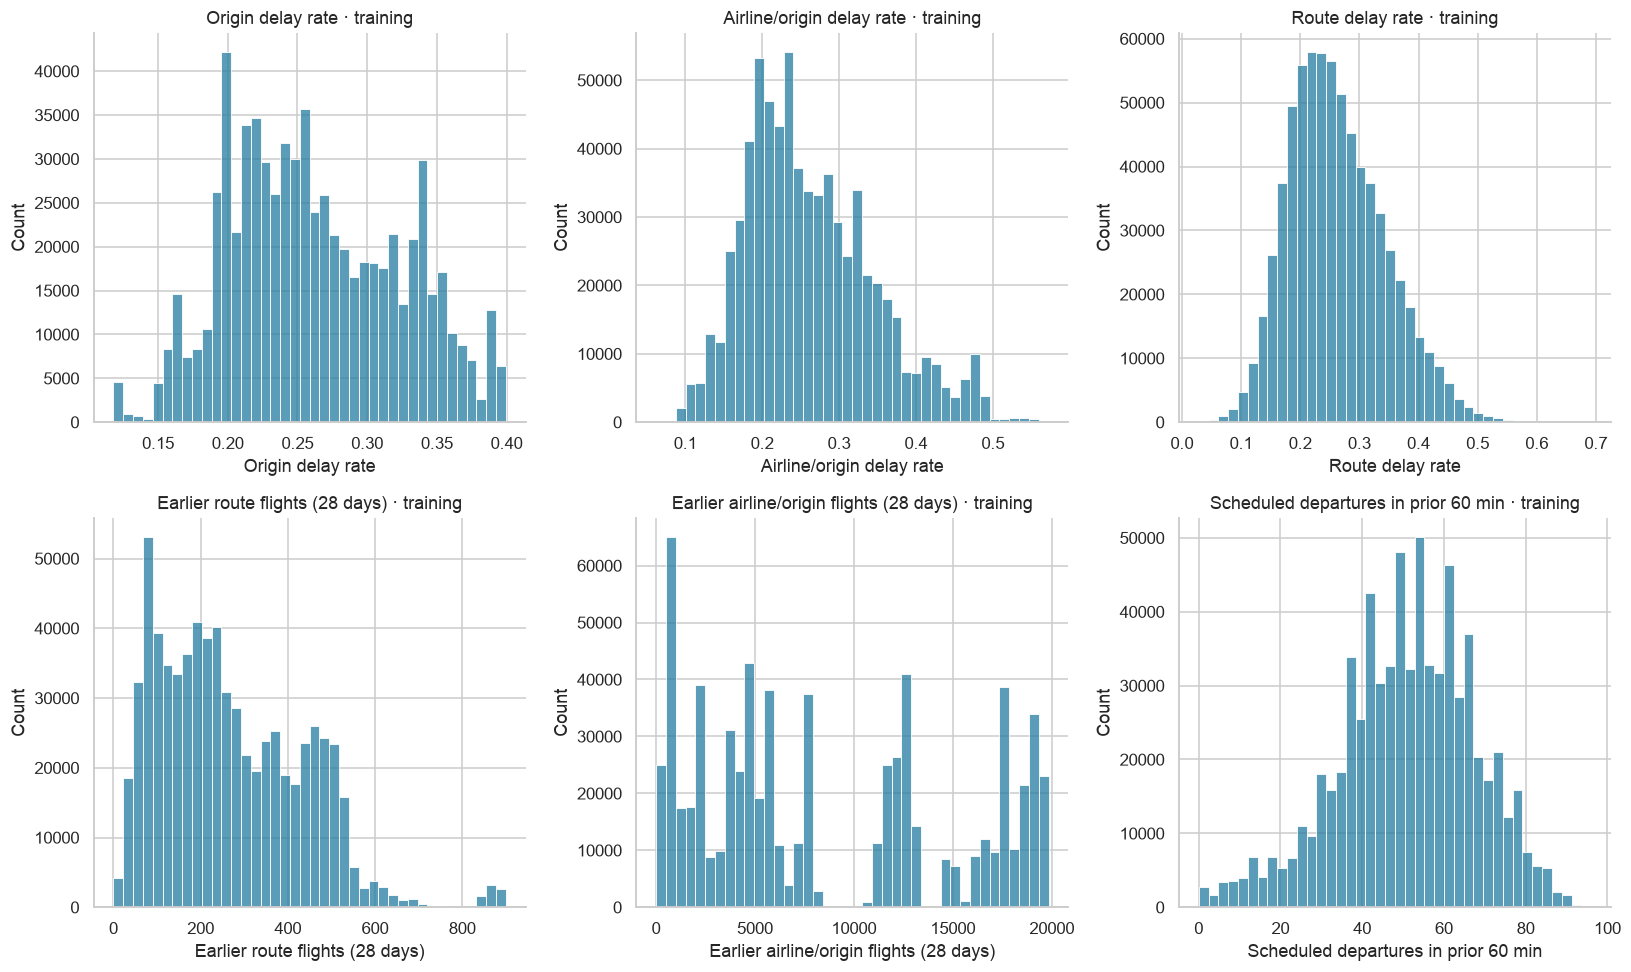

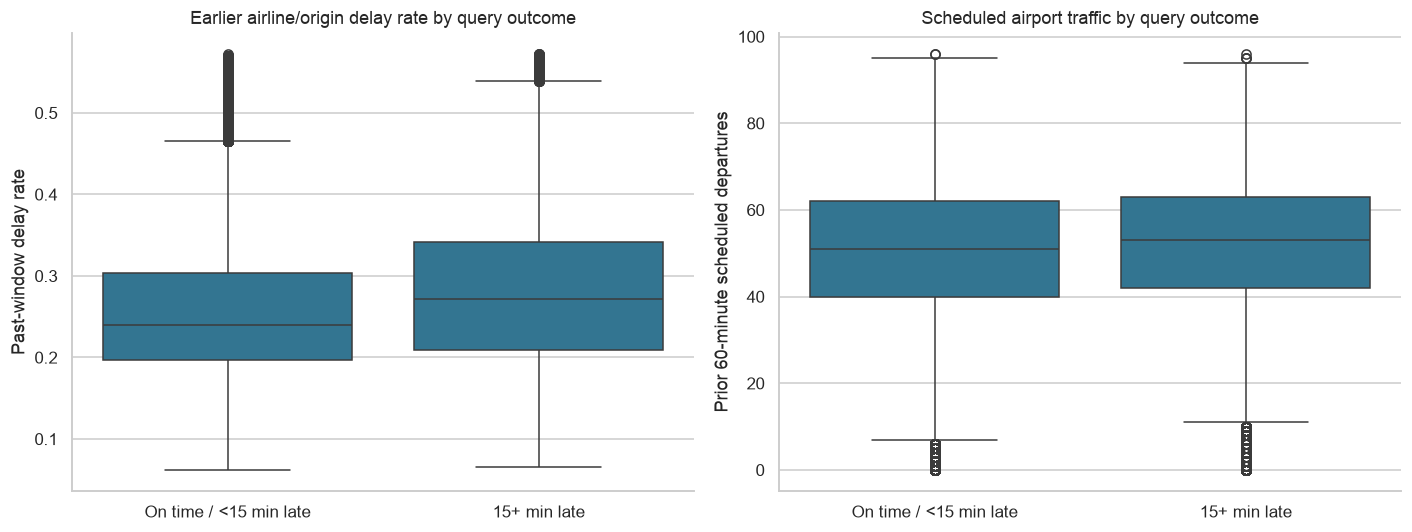

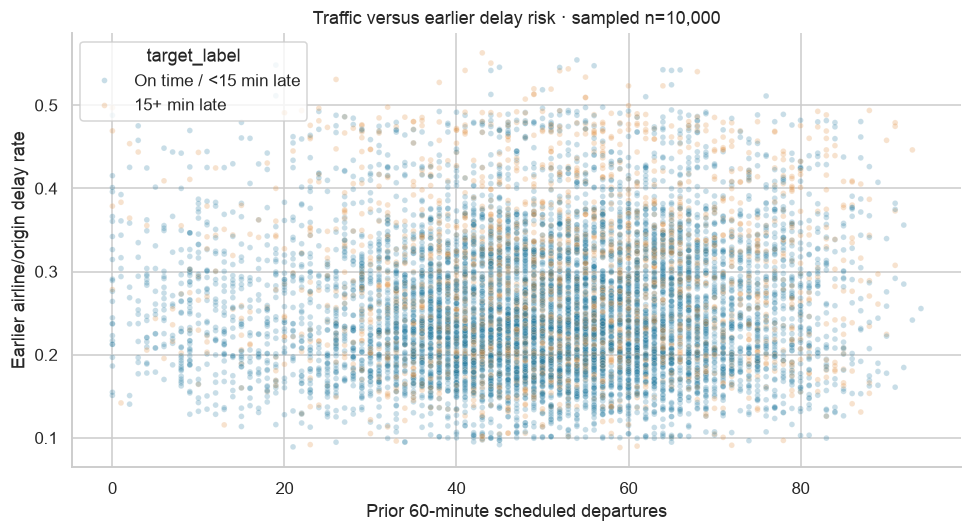

In [14]:
train_features = features.loc[features['split'].eq('train')].copy()
train_features['target_label'] = train_features['delayed_departure'].map({0: 'On time / <15 min late', 1: '15+ min late'})
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
history_plot_columns = ['history_origin_rate', 'history_airline_origin_rate', 'history_route_rate',
                         'history_route_n', 'history_airline_origin_n', 'airport_scheduled_departures_prior_60m']
history_plot_labels = ['Origin delay rate', 'Airline/origin delay rate', 'Route delay rate',
                       'Earlier route flights (28 days)', 'Earlier airline/origin flights (28 days)',
                       'Scheduled departures in prior 60 min']
for column, label, ax in zip(history_plot_columns, history_plot_labels, axes.flat):
    sns.histplot(data=train_features, x=column, bins=40, ax=ax)
    ax.set(title=f'{label} · training', xlabel=label)
show_plot()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=train_features, x='target_label', y='history_airline_origin_rate', ax=axes[0])
axes[0].set(title='Earlier airline/origin delay rate by query outcome', xlabel='', ylabel='Past-window delay rate')
sns.boxplot(data=train_features, x='target_label', y='airport_scheduled_departures_prior_60m', ax=axes[1])
axes[1].set(title='Scheduled airport traffic by query outcome', xlabel='', ylabel='Prior 60-minute scheduled departures')
show_plot()

scatter = train_features.sample(n=min(10_000, len(train_features)), random_state=SEED)
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=scatter, x='airport_scheduled_departures_prior_60m', y='history_airline_origin_rate',
                hue='target_label', alpha=.25, s=14, ax=ax)
ax.set(title=f'Traffic versus earlier delay risk · sampled n={len(scatter):,}',
       xlabel='Prior 60-minute scheduled departures', ylabel='Earlier airline/origin delay rate')
show_plot()


### Recheck created variables

Summarize newly created rates and counts, including cardinality and skewness. Their meanings differ from binary missingness flags.


In [15]:
created_review_columns = ['history_origin_rate', 'history_airline_origin_rate', 'history_route_rate',
                           'history_route_n', 'history_airline_origin_n', 'airport_scheduled_departures_prior_60m']
created_summary = train_features[created_review_columns].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
created_summary['unique_nonmissing'] = train_features[created_review_columns].nunique()
show_table(created_summary)


                                           count         mean       median          std       min           max      skew  unique_nonmissing
history_origin_rate                     698670.0     0.262097     0.254431     0.061105  0.118005      0.399477  0.228863             191592
history_airline_origin_rate             698670.0     0.262218     0.246058     0.084082  0.062016      0.572302  0.685713             404011
history_route_rate                      698670.0     0.262549     0.252713     0.081615  0.028277      0.691884  0.516814             678938
history_route_n                         698670.0   265.834652   235.000000   165.214710  0.000000    900.000000  0.767895                892
history_airline_origin_n                698670.0  8662.692576  6457.000000  6467.673582  0.000000  19831.000000  0.354445              14745
airport_scheduled_departures_prior_60m  698670.0    50.745172    52.000000    16.773908  0.000000     96.000000 -0.362817                 97


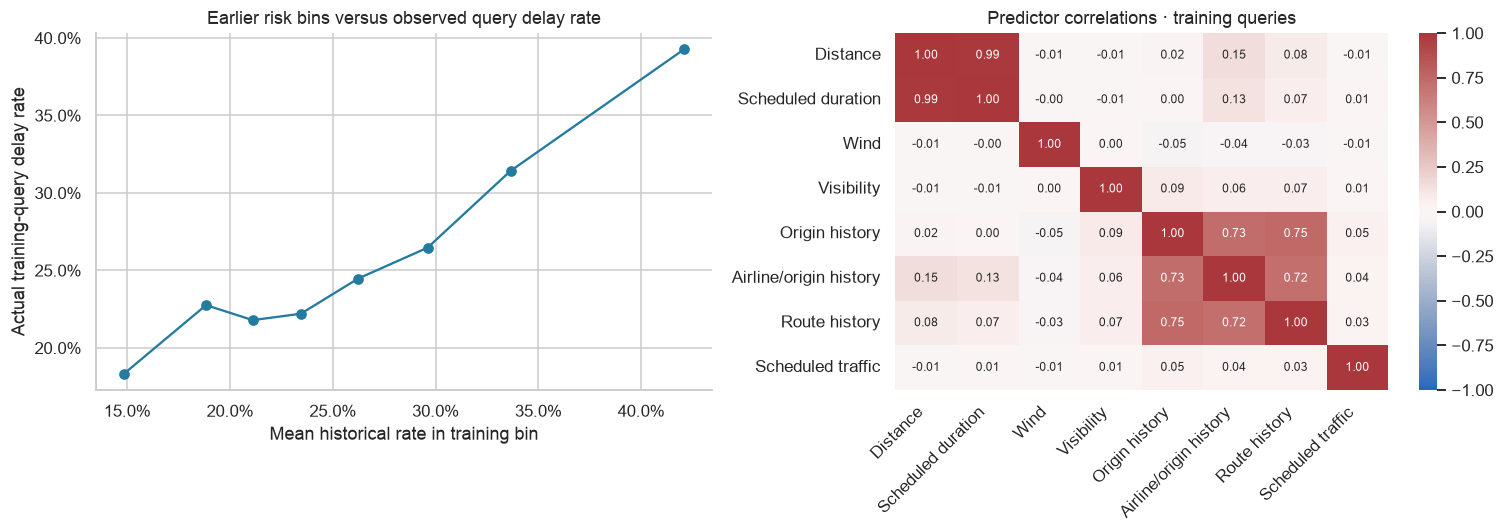

                    n  delayed  mean_historical_rate  query_delay_rate
history_bin                                                           
(0.061, 0.175]  87334    16009              0.148394          0.183308
(0.175, 0.2]    87334    19877              0.188324          0.227597
(0.2, 0.224]    87339    19033              0.211003          0.217921
(0.224, 0.246]  87330    19390              0.234423          0.222031
(0.246, 0.279]  87332    21373              0.262302          0.244733
(0.279, 0.317]  87334    23112              0.296052          0.264639
(0.317, 0.362]  87334    27441              0.336426          0.314208
(0.362, 0.572]  87333    34292              0.420825          0.392658


In [16]:
history_bins = pd.qcut(train_features['history_airline_origin_rate'], q=8, duplicates='drop')
binned = train_features.assign(history_bin=history_bins).groupby('history_bin', observed=True).agg(
    n=('flight_id', 'size'), delayed=('delayed_departure', 'sum'),
    mean_historical_rate=('history_airline_origin_rate', 'mean'))
binned['query_delay_rate'] = binned['delayed'] / binned['n']
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(binned['mean_historical_rate'], binned['query_delay_rate'], marker='o')
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title='Earlier risk bins versus observed query delay rate',
            xlabel='Mean historical rate in training bin', ylabel='Actual training-query delay rate')
corr_columns = ['distance_miles', 'scheduled_duration_minutes', 'wind_knots', 'visibility_miles',
                 'history_origin_rate', 'history_airline_origin_rate', 'history_route_rate',
                 'airport_scheduled_departures_prior_60m']
corr_labels = ['Distance', 'Scheduled duration', 'Wind', 'Visibility', 'Origin history',
               'Airline/origin history', 'Route history', 'Scheduled traffic']
corr = train_features[corr_columns].corr().set_axis(corr_labels).set_axis(corr_labels, axis=1)
sns.heatmap(corr, cmap='vlag', vmin=-1, vmax=1,
            annot=True, fmt='.2f', ax=axes[1], annot_kws={'size': 8})
axes[1].set_title('Predictor correlations · training queries')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
show_plot()
show_table(binned)


## Feature allowlists and shared sampling

This is where model sampling actually happens. Keep all eligible rows in the saved table. The model_sample flag selects 20,000 initial-training, 5,000 validation and 10,000 test flights, proportionally within month × outcome strata using seed 42. Every A/B and classifier comparison uses those same IDs.

The separate refit_sample flag selects 20,000 flights proportionally from all 12 months of 2025. It may overlap the development samples, but never the 2026 test. Use it only after all model, feature, setting and threshold choices are frozen; refit preprocessing from scratch then. This is not another validation period. A full-2025 sample covers the year without fitting KNN/SVM on nearly a million rows.


In [17]:
from sklearn.model_selection import train_test_split

CATEGORICAL_FEATURES = ['airline', 'origin', 'destination', 'weekday']
A_NUMERIC = ['distance_miles', 'scheduled_duration_minutes', 'departure_sin', 'departure_cos', 'month_sin', 'month_cos']
HISTORY_FEATURES = [prefix + suffix for prefix, _ in history_definitions
                     for suffix in ['_rate', '_n', '_no_history']]
B_NUMERIC = A_NUMERIC + WEATHER_FEATURES + ['weather_age_minutes', 'weather_report_missing'] + HISTORY_FEATURES + ['airport_scheduled_departures_prior_60m']
FEATURE_SETS = {'A': CATEGORICAL_FEATURES + A_NUMERIC,
                'B': CATEGORICAL_FEATURES + B_NUMERIC}
FORBIDDEN = {'delayed_departure', 'departure_delay_minutes', 'departure_delay_15_source',
    'cancelled', 'diverted', 'departure_outcome_event_utc', 'flight_id', 'flight_number',
    'Tail_Number', 'tail_number', 'LateAircraftDelay', 'weather_source_file'}
for name, columns in FEATURE_SETS.items():
    assert len(columns) == len(set(columns))
    assert not FORBIDDEN.intersection(columns)
    assert set(columns).issubset(features.columns)
    assert not features[columns].select_dtypes(include=['datetime', 'datetimetz']).columns.tolist()
assert set(FEATURE_SETS['A']).issubset(FEATURE_SETS['B'])

def sample_indices(population, desired):
    if len(population) < desired:
        raise ValueError(f'Population has fewer than {desired:,} rows; clarify sample size.')
    if desired == len(population):
        return population.index
    strata = population['month'].astype(str) + '|' + population['delayed_departure'].astype(str)
    if strata.value_counts().min() < 2:
        raise ValueError('Sparse month/outcome stratum; clarify sampling policy.')
    selected, _ = train_test_split(population.index, train_size=desired,
                                    random_state=SEED, stratify=strata)
    return selected

features['model_sample'] = False
sample_summary = []
for split_name in ['train', 'validation', 'test']:
    population = features.loc[features['split'].eq(split_name)]
    selected = sample_indices(population, CONFIG['sampling'][split_name + '_rows'])
    features.loc[selected, 'model_sample'] = True
    sample_summary.append({'split': split_name, 'population_rows': len(population),
                           'sample_rows': len(selected), 'seed': SEED, 'same_A_B_ids': True})

# A separate flag covers all 12 months for the final fit AFTER validation selection.
refit_population = features.loc[features['flight_date'].between(
    CONFIG['split']['refit_start'], CONFIG['split']['refit_end'])]
features['refit_sample'] = features.index.isin(
    sample_indices(refit_population, CONFIG['sampling']['refit_rows']))
assert not features.loc[features['refit_sample'], 'split'].eq('test').any()
assert set(features.loc[features['refit_sample'], 'month']) == set(range(1, 13))
show_table(pd.DataFrame(sample_summary + [{
    'split': 'final refit (2025 only)', 'population_rows': len(refit_population),
    'sample_rows': int(features['refit_sample'].sum()), 'seed': SEED, 'same_A_B_ids': True}]))
show_table(pd.DataFrame({'feature_set': ['A', 'B'],
                      'categorical_features': [len(CATEGORICAL_FEATURES)] * 2,
                      'numeric_features': [len(A_NUMERIC), len(B_NUMERIC)]}))
print('Month/outcome stratification preserves proportions; it does not balance the delay classes.')
print('Test labels are used only by the frozen sampling rule; no test delay rates or relationships are inspected.')


                     split  population_rows  sample_rows  seed  same_A_B_ids
0                    train           698670        20000    42          True
1               validation           239747         5000    42          True
2                     test           219748        10000    42          True
3  final refit (2025 only)           938417        20000    42          True
  feature_set  categorical_features  numeric_features
0           A                     4                 6
1           B                     4                33
Month/outcome stratification preserves proportions; it does not balance the delay classes.
Test labels are used only by the frozen sampling rule; no test delay rates or relationships are inspected.


## 6. Training-only preprocessing preview

Use median imputation and categorical one-hot encoding. Month and clock already use fixed cyclic coordinates. Scale numeric inputs for Logistic Regression/KNN/SVM; Random Forest can use the same recipe without scaling.

Four condition flags share an explicit condition_codes_missing flag. Cloud-state flags already explain absent ceiling values. Skip redundant automatic indicators for those columns, while preserving useful automatic indicators such as absent wind/gust.

Fit this preview on initial training only and transform validation. Final model pipelines must fit their own fresh preprocessing; the final refit later uses refit_sample. No test outcomes are analysed here.


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(feature_set='B', scale_numeric=True):
    numeric = A_NUMERIC if feature_set == 'A' else B_NUMERIC
    if feature_set not in FEATURE_SETS:
        raise ValueError('Only A and B are in the agreed scope.')
    covered = CONFIG['preprocessing']['explicit_missingness_covered_columns']
    groups = [('numeric', [c for c in numeric if c not in covered], True),
              ('explicit_flags', [c for c in numeric if c in covered], False)]
    transformers = []
    for name, columns, indicators in groups:
        if columns:
            steps = [('imputer', SimpleImputer(strategy='median', add_indicator=indicators,
                                               keep_empty_features=True))]
            if scale_numeric:
                steps.append(('scaler', StandardScaler()))
            transformers.append((name, Pipeline(steps), columns))
    categories = Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown', keep_empty_features=True)),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=True, dtype=np.float64)),
    ])
    transformers.append(('categorical', categories, CATEGORICAL_FEATURES))
    return ColumnTransformer(transformers, remainder='drop', sparse_threshold=1.0)

training_rows = features['split'].eq('train') & features['model_sample']
validation_rows = features['split'].eq('validation') & features['model_sample']
preview_preprocessor = make_preprocessor('B', scale_numeric=True)
X_train_preview = preview_preprocessor.fit_transform(features.loc[training_rows, FEATURE_SETS['B']])
X_validation_preview = preview_preprocessor.transform(features.loc[validation_rows, FEATURE_SETS['B']])
show_table(pd.DataFrame({'partition': ['training preview', 'validation preview'],
                      'rows': [X_train_preview.shape[0], X_validation_preview.shape[0]],
                      'transformed_columns': [X_train_preview.shape[1], X_validation_preview.shape[1]]}))
assert X_train_preview.shape[1] == X_validation_preview.shape[1]
print('Preprocessing fitted on training only. No transformed matrix is exported.')

names = preview_preprocessor.get_feature_names_out()
assert not any('missingindicator_' + c in name for c in CONFIG['preprocessing']['explicit_missingness_covered_columns'] for name in names)
for matrix in [X_train_preview, X_validation_preview]:
    assert np.isfinite(matrix.data if hasattr(matrix, 'toarray') else matrix).all()
print('No repeated condition/ceiling indicators; transformed values are finite.')


            partition   rows  transformed_columns
0    training preview  20000                  293
1  validation preview   5000                  293
Preprocessing fitted on training only. No transformed matrix is exported.
No repeated condition/ceiling indicators; transformed values are finite.


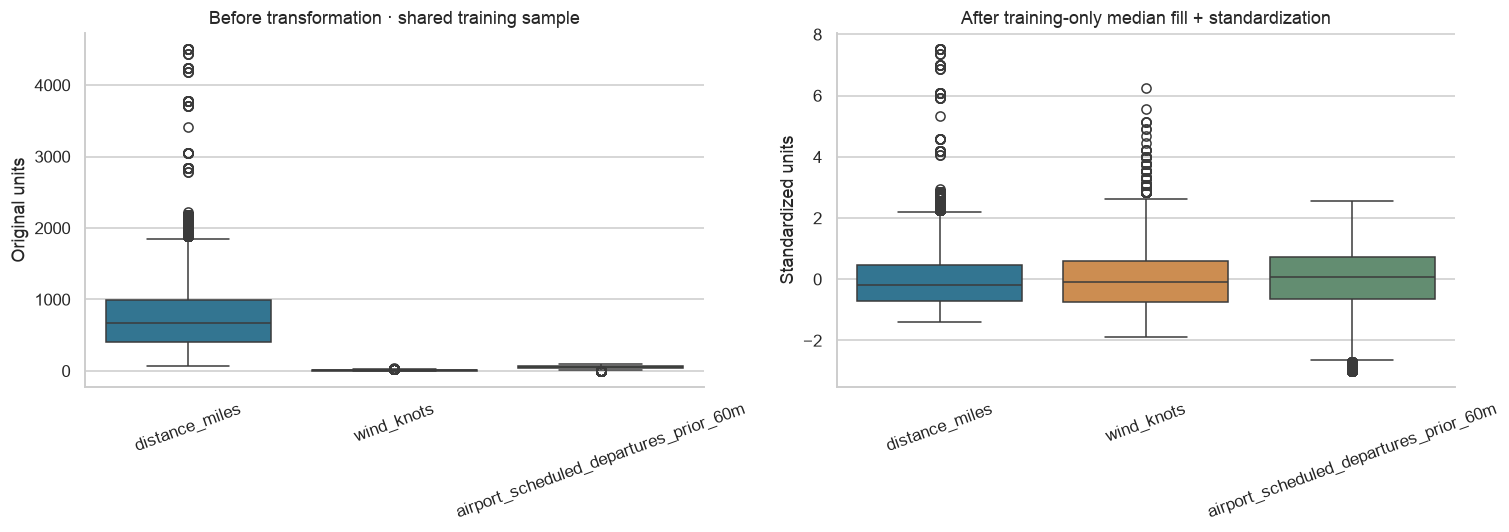

     original_traffic  log1p_traffic
56                 48       3.891820
197                 9       2.302585
230                34       3.555348
237                35       3.583519
255                64       4.174387
  representation  skewness
original traffic -0.402179
   log1p traffic -3.019348


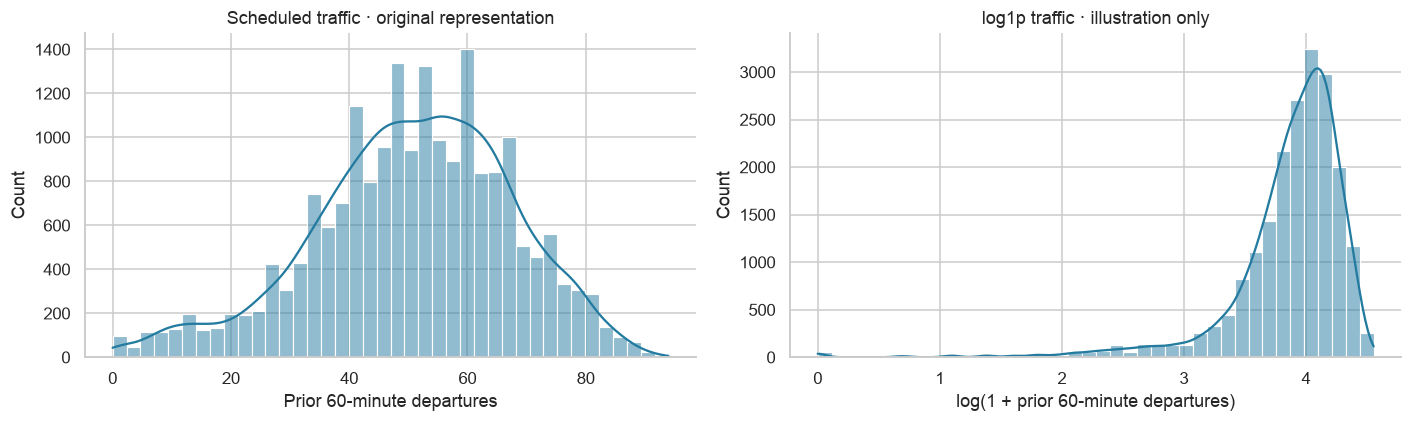

Transformation decision: cyclic month/clock coordinates and one-hot weekday/airline/airport categories are the initial recipe. The log1p illustration is not added to A/B automatically. No target transformation or outlier capping is applied.


In [19]:
# Before/after plots use a separate small numerical preview for readability.
transform_plot_columns = ['distance_miles', 'wind_knots', 'airport_scheduled_departures_prior_60m']
train_input = features.loc[training_rows, transform_plot_columns]
plot_recipe = Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                        ('scaler', StandardScaler())])
train_standardized = pd.DataFrame(plot_recipe.fit_transform(train_input),
                                  columns=transform_plot_columns, index=train_input.index)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=train_input, ax=axes[0])
axes[0].set(title='Before transformation · shared training sample', ylabel='Original units')
sns.boxplot(data=train_standardized, ax=axes[1])
axes[1].set(title='After training-only median fill + standardization', ylabel='Standardized units')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
show_plot()

traffic_original = train_input['airport_scheduled_departures_prior_60m']
traffic_log = np.log1p(traffic_original)
show_table(pd.DataFrame({'original_traffic': traffic_original, 'log1p_traffic': traffic_log}).head())
show_table(pd.DataFrame({'representation': ['original traffic', 'log1p traffic'],
                    'skewness': [traffic_original.skew(), traffic_log.skew()]}), index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(traffic_original, bins=40, kde=traffic_original.nunique() > 1, ax=axes[0])
axes[0].set(title='Scheduled traffic · original representation', xlabel='Prior 60-minute departures')
sns.histplot(traffic_log, bins=40, kde=traffic_log.nunique() > 1, ax=axes[1])
axes[1].set(title='log1p traffic · illustration only', xlabel='log(1 + prior 60-minute departures)')
show_plot()
print('Transformation decision: cyclic month/clock coordinates and one-hot weekday/airline/airport categories are the initial recipe. The log1p illustration is not added to A/B automatically. No target transformation or outlier capping is applied.')


## Feature dictionary, checks and handoff

Display the complete definitions from `config/project.json`. Calculations remain above. Save one unscaled feature table with labels, shared sample membership and audit fields; update the shared manifest. No split CSVs or transformed-matrix files are written.


In [20]:
feature_dictionary = CONFIG['feature_dictionary']
assert [item['feature'] for item in feature_dictionary] == FEATURE_SETS['B']
show_table(pd.DataFrame(feature_dictionary))

assert features['flight_id'].is_unique and len(features) == len(queries)
assert features['flight_id'].equals(queries['flight_id'])
assert features['delayed_departure'].equals(queries['delayed_departure'])
assert not features.loc[features['model_sample'], 'split'].eq('context').any()
assert (features['prediction_cutoff_utc'] < features['scheduled_departure_utc']).all()
for prefix, _ in history_definitions:
    mask = features[prefix + '_n'].gt(0)
    assert (features.loc[mask, prefix + '_latest_event_utc'] < history_end.loc[mask]).all()

def file_sha256(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

sample_cohort = features.loc[features['model_sample'], ['flight_id', 'delayed_departure']].sort_values('flight_id')
cohort_fingerprint = hashlib.sha256(pd.util.hash_pandas_object(sample_cohort, index=False).values.tobytes()).hexdigest()
audit_columns = ['flight_id', 'source_file', 'source_row_number', 'flight_date', 'split', 'model_sample', 'refit_sample', 'month',
    'scheduled_departure_utc', 'prediction_cutoff_utc', 'departure_time_band', 'delayed_departure',
    'weather_lookup_utc', 'weather_observed_utc', 'weather_source_file']
audit_columns += [prefix + '_latest_event_utc' for prefix, _ in history_definitions]
keep_columns = list(dict.fromkeys(audit_columns + FEATURE_SETS['B']))
feature_output = features[keep_columns].copy()

if WRITE_OUTPUTS:
    output = ROOT / 'data/processed/features.parquet'
    feature_output.to_parquet(output, engine='pyarrow', index=False, compression='zstd')
    manifest = json.loads(manifest_path.read_text())
    manifest['feature_engineering'] = {
        'completed_at_utc': datetime.now(timezone.utc).isoformat(),
        'input': 'data/processed/flights_clean.parquet', 'input_sha256': file_sha256(clean_path),
        'output': 'data/processed/features.parquet', 'output_sha256': file_sha256(output),
        'rows': len(feature_output), 'feature_sets': FEATURE_SETS, 'feature_dictionary': feature_dictionary,
        'split_definition': CONFIG['split'],
        'shared_samples': sample_summary, 'sample_cohort_fingerprint': cohort_fingerprint,
        'final_refit': {'rows': int(features['refit_sample'].sum()),
            'cohort_fingerprint': hashlib.sha256(pd.util.hash_pandas_object(
                features.loc[features['refit_sample'], ['flight_id', 'delayed_departure']].sort_values('flight_id'),
                index=False).values.tobytes()).hexdigest(),
            'policy': CONFIG['sampling']['refit_policy']},
        'preprocessing': CONFIG['preprocessing'],
        'test_outcome_policy': CONFIG['evaluation_extension']['test_outcome_policy'],
        'weather': {'source_batches': weather_source_log, 'raw_scope_rows': weather_raw_rows,
            'exact_duplicate_payloads_removed': exact_weather_duplicates,
            'conflicting_station_time_policy': CONFIG['weather_quality']['conflict_policy'],
            'excluded_conflicting_station_times': weather_conflicts.to_dict('records'),
            'conflicting_report_versions_excluded': int(conflict.sum()),
            'unreviewed_conflicts': 'stop and clarify',
            'buffer_minutes': WEATHER_BUFFER_MINUTES, 'max_age_minutes': WEATHER_MAX_AGE_MINUTES,
            'treatments': weather_treatment_log,
            'cloud_extraction': 'All METAR body layers before RMK, with structured sky-column fallback; unknown ceiling heights remain missing'}, 
        'history': {'window_days': HISTORY_DAYS, 'lag_days': HISTORY_LAG_DAYS,
            'subgroup_prior_strength': HISTORY_PRIOR_STRENGTH,
            'event_definition': 'scheduled departure UTC + reported departure delay',
            'scope': 'ATL/ORD/DFW; airline-origin and route-origin histories',
            'evaluation_policy': 'Frozen rolling rule; earlier 2026 outcomes may enter later test histories only after the seven-day lag. No classifier is refitted on 2026.'},
        'traffic': 'All scheduled origin departures in [query scheduled departure-60m, query scheduled departure)',
        'study_design': 'Historical simulation with unverified weather/outcome receipt and schedule-availability assumptions',
        'preprocessor_preview_only': True, 'classifiers_trained': False,
    }
    manifest_path.write_text(json.dumps(manifest, indent=2, default=str) + '\n')
    print(f'Saved {output.relative_to(ROOT)}: {len(feature_output):,} queries, shared sample flags included.')
    print('Prepared data must be reviewed before notebook 03 model training.')
else:
    print('WRITE_OUTPUTS=False: feature table and manifest were not written.')


                                   feature in_sets    family                                                                                                                  definition                                                                           source                                                                                             missing_treatment                                                           availability
0                                  airline  [A, B]  schedule                                                                                                           Reporting airline                                                            BTS Reporting_Airline                                                       Training-fitted constant Unknown, then one-hot encoding                                        Archived schedule assumed known
1                                   origin  [A, B]  schedule                                              

Saved data/processed/features.parquet: 1,158,165 queries, shared sample flags included.
Prepared data must be reviewed before notebook 03 model training.


## Review and next stage

The run saved **1,158,165 eligible queries**: 698,670 initial-training, 239,747 validation and 219,748 final-test rows. A has 10 predictors; B has 37. The training-only preview has 293 transformed columns. Sample flags select 20,000 / 5,000 / 10,000 flights plus a separate 20,000-flight full-2025 refit sample. A/B share identical flights. The saved feature table keeps all eligible queries, raw month for audit, and separate model_sample and refit_sample flags.

Weather matching and field completeness are different checks: a matched report can still have unknown gusts, cloud heights or condition codes. Eight approved ambiguous station/times are excluded under the same earlier-report fallback. New conflicts stop for review.

History uses a frozen rolling window. During Q1 testing, an earlier 2026 departure may contribute to a later flight's history only after the seven-day lag, under the stated timely-feed assumption. This simulates sequential prediction; it does not retrain the classifier or allow test-based feature selection.

Notebook 03 remains the modelling stage: select on 2025 validation, freeze choices, refit on refit_sample, then evaluate once on the 2026 test sample and export predictions for Tableau. No classifier or Tableau results exist yet.

[IEM variables](https://mesonet.agron.iastate.edu/request/download.phtml) · [Objectives](../OBJECTIVES.md) · [Tableau exports](../tableau/export_contract.json)


## Additional feature engineering · a new development experiment

The sections above preserve the original preparation run. Models 03–05 have since been completed, and both 2026 test quarters have been examined. **This appendix uses 2025 development flights only**, with November–December 2024 as history context. All outcome plots remain January–September 2025 only.

We first rebuild the existing 66-predictor improvement recipe, then add three candidate groups:
1. **Relative traffic:** scheduled hourly departures compared with earlier activity at the same airport, weekday and local hour.
2. **Weather × traffic:** interactions that may capture weather having different effects at different traffic levels.
3. **Different history windows:** 7-day and 42-day reliability, plus their difference. Both end seven days before the prediction cutoff.

A 56-day window would need late-October 2024 context that we do not have. The 42-day window has complete calendar coverage. These are hypotheses, not demonstrated F1 improvements. No classifier is fitted here; selecting features will require a separate chronological validation experiment.

**Run from this heading in a fresh kernel** to review the appendix without rerunning the original save cells. It writes no datasets, manifests, models or Tableau exports. The current results remain the benchmark.


In [1]:
from pathlib import Path
import site, sys, json, hashlib
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if (ROOT / 'departure-delay-classification/config/project.json').is_file():
    ROOT /= 'departure-delay-classification'
CONFIG = json.loads((ROOT / 'config/project.json').read_text())
PREP = json.loads((ROOT / 'reports/preparation_manifest.json').read_text())['feature_engineering']
FROZEN = json.loads((ROOT / 'reports/improvements/selection.json').read_text())
SEED, LAG_DAYS, LONG_DAYS, PRIOR = 42, 7, 42, 20

def extension_sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

protected_paths = ['data/processed/features.parquet', 'data/processed/flights_clean.parquet',
                  'reports/preparation_manifest.json', 'reports/improvements/selection.json',
                  'models/improved_flight_delay_models.joblib']
protected_before = {p: extension_sha(ROOT / p) for p in protected_paths}
assert protected_before['data/processed/features.parquet'] == FROZEN['feature_input_sha256']
assert extension_sha(ROOT / 'scripts/improvement_features.py') == FROZEN['helper_sha256']
sys.path.insert(0, str(ROOT / 'scripts'))
from improvement_features import (TIME_FEATURES, FLIGHT_FEATURES, WEATHER_NEW,
                                  load_weather, add_time, add_weather, add_histories)

development = pd.read_parquet(ROOT / PREP['output'], filters=[
    ('flight_date', '>=', pd.Timestamp('2025-01-01')),
    ('flight_date', '<', pd.Timestamp('2026-01-01'))]).reset_index(drop=True)
context = pd.read_parquet(ROOT / 'data/processed/flights_clean.parquet', columns=[
    'flight_id', 'flight_date', 'origin', 'airline', 'destination', 'flight_number',
    'scheduled_departure_minutes', 'scheduled_departure_utc', 'label_eligible',
    'departure_outcome_event_utc', 'delayed_departure'],
    filters=[('flight_date', '<', pd.Timestamp('2026-01-01'))])
assert development['flight_id'].is_unique and context['flight_id'].is_unique
original_ids = development['flight_id'].copy()
train_mask = development['split'].eq('train')
assert development['flight_date'].dt.year.eq(2025).all()
assert development['split'].isin(['train', 'validation']).all()
assert context['flight_date'].max() < pd.Timestamp('2026-01-01')
sns.set_theme(style='whitegrid', palette=['#247BA0', '#E08D3C', '#5C946E'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def extension_table(frame, **kwargs):
    print(frame.to_string(**kwargs))

def extension_plot():
    plt.tight_layout()
    plt.show()

extension_table(development.groupby('split', observed=True).size().to_frame('retained_flights'))


            retained_flights
split                       
train                 698670
validation            239747


### Carry forward the features already tested in notebook 04

Reuse its frozen helper rather than rewriting the time, flight-number history and weather-trend calculations. Weather is loaded from the 2025 batches only, using the already approved conflict exclusions. The rule remains latest observation before cutoff−20 minutes, no more than 180 minutes old. This reconstructs predictors; it performs no model selection or fitting.


In [2]:
source_lookup = context.set_index('flight_id')
for column in ['flight_number', 'scheduled_departure_minutes']:
    development[column] = development['flight_id'].map(source_lookup[column])
assert development[['flight_number', 'scheduled_departure_minutes']].notna().all().all()
events = context.loc[context['label_eligible']].copy()
weather_extension, weather_extension_audit = load_weather(
    ROOT, [2025], CONFIG['weather_quality']['excluded_station_times'])
development = add_time(add_histories(add_weather(development, weather_extension), events))
CURRENT_B = PREP['feature_sets']['B'] + TIME_FEATURES + FLIGHT_FEATURES + WEATHER_NEW
assert FROZEN['chosen_feature_package'] == 'time_flight_weather'
assert CURRENT_B == next(c['columns'] for c in FROZEN['choices'] if c['feature_set'] == 'B')
assert development['flight_id'].equals(original_ids)
assert len(CURRENT_B) == len(set(CURRENT_B)) == 66
candidate_features = pd.DataFrame(index=development.index)
window_audit = {}
del weather_extension, source_lookup
print(f'Rebuilt {len(CURRENT_B)} existing predictors for {len(development):,} development flights.')


Rebuilt 66 existing predictors for 938,417 development flights.


### One explicit rule for earlier windows

For each flight, use events in **[cutoff − 7 days − window, cutoff − 7 days)**. The left boundary is included; the right boundary is excluded. Counts and cumulative sums avoid one slow row-by-row calculation per flight. We check the latest contributing timestamp for every nonempty window.

For outcomes, the event time is the earlier flight's observed departure. For traffic reference hours, it is the **end** of the fully observed hourly schedule slot. These checks enforce temporal ordering; timely outcome delivery and archived schedule availability remain historical-simulation assumptions.


In [3]:
def past_window_totals(query, reference, groups, time_column, value_column, days):
    end = (pd.to_datetime(query['prediction_cutoff_utc'], utc=True)
           .astype('datetime64[ns, UTC]') - pd.Timedelta(days=LAG_DAYS))
    start = end - pd.Timedelta(days=days)
    n = np.zeros(len(query), dtype='int32')
    total = np.zeros(len(query), dtype='float64')
    latest = np.full(len(query), np.iinfo('int64').min, dtype='int64')
    reference_groups = reference.groupby(groups, observed=True, dropna=False).indices
    for key, positions in query.groupby(groups, observed=True, dropna=False).indices.items():
        if key not in reference_groups:
            continue
        block = reference.iloc[reference_groups[key]].sort_values(time_column)
        times = pd.to_datetime(block[time_column], utc=True).astype('datetime64[ns, UTC]').array.asi8
        values = block[value_column].to_numpy(dtype='float64')
        assert np.isfinite(values).all()
        cumulative = np.r_[0., values.cumsum()]
        left = np.searchsorted(times, start.array.asi8[positions], side='left')
        right = np.searchsorted(times, end.array.asi8[positions], side='left')
        n[positions], total[positions] = right - left, cumulative[right] - cumulative[left]
        present = right > left
        latest[positions[present]] = times[right[present] - 1]
    latest = pd.Series(pd.to_datetime(latest, utc=True), index=query.index)
    present = n > 0
    assert (latest.loc[present] >= start.loc[present]).all()
    assert (latest.loc[present] < end.loc[present]).all()
    return n, total, latest


### 1. Traffic relative to earlier comparable hours

Count **all scoped schedules**, including flights later cancelled, in each actual UTC hour. Convert each slot to its airport's local weekday and hour. An hourly grid includes zero-departure hours; daylight-saving changes keep distinct actual hours.

Compare the query's scheduled departure hour with matching weekday/hour slots in the previous 42-day reference window, ending seven days before cutoff. Ratio 1 means the reference mean; 1.5 means 50% more scheduled departures. This measures **schedule demand**, not runway capacity or actual congestion. It assumes the archived schedule was known at the prediction time. A zero reference mean leaves the ratio unknown and sets a flag; we do not invent a denominator.

The raw ratio is retained for inspection. The candidate models use `log(1 + ratio)` to reduce the influence of very small reference means without deleting or capping valid observations. Rain/thunder interactions below use that transformed demand measure. The reference-hour count remains an audit field.


In [4]:
hour_blocks = []
traffic_query = development[['origin', 'prediction_cutoff_utc']].copy()
traffic_query['local_weekday'] = 0
traffic_query['local_hour'] = 0
zones = json.loads((ROOT / 'reports/preparation_manifest.json').read_text())['cleaning']['origin_timezones_from_raw']
for origin, zone in zones.items():
    schedules = context.loc[context['origin'].eq(origin)]
    start = schedules['flight_date'].min().tz_localize(zone).tz_convert('UTC')
    stop = (schedules['flight_date'].max() + pd.Timedelta(days=1)).tz_localize(zone).tz_convert('UTC')
    hours = pd.date_range(start, stop, freq='h', inclusive='left')
    counts = schedules.groupby(schedules['scheduled_departure_utc'].dt.floor('h')).size().reindex(hours, fill_value=0)
    local = hours.tz_convert(zone)
    hour_blocks.append(pd.DataFrame({'origin': origin, 'hour_utc': hours,
        'hour_end_utc': hours + pd.Timedelta(hours=1), 'local_weekday': local.dayofweek,
        'local_hour': local.hour, 'scheduled_departures': counts.to_numpy()}))
    positions = development['origin'].eq(origin)
    local_query = development.loc[positions, 'scheduled_departure_utc'].dt.tz_convert(zone)
    traffic_query.loc[positions, 'local_weekday'] = local_query.dt.dayofweek.to_numpy()
    traffic_query.loc[positions, 'local_hour'] = local_query.dt.hour.to_numpy()
hour_reference = pd.concat(hour_blocks, ignore_index=True)
assert not hour_reference.duplicated(['origin', 'hour_utc']).any()
reference_start = hour_reference.groupby('origin', observed=True)['hour_utc'].min()
needed_start = development['prediction_cutoff_utc'] - pd.Timedelta(days=LAG_DAYS + LONG_DAYS)
assert (needed_start >= development['origin'].map(reference_start)).all(), 'Incomplete schedule warm-up.'

n, total, latest = past_window_totals(traffic_query, hour_reference,
    ['origin', 'local_weekday', 'local_hour'], 'hour_end_utc', 'scheduled_departures', LONG_DAYS)
mean = np.divide(total, n, out=np.full(len(n), np.nan), where=n > 0)
keys = pd.MultiIndex.from_arrays([development['origin'], development['scheduled_departure_utc'].dt.floor('h')])
current = hour_reference.set_index(['origin', 'hour_utc'])['scheduled_departures'].reindex(keys).to_numpy()
assert np.isfinite(current).all()
candidate_features['traffic_hour_departures'] = current
candidate_features['traffic_expected_hour'] = mean
candidate_features['traffic_relative_hour'] = np.divide(current, mean, out=np.full(len(n), np.nan), where=mean > 0)
candidate_features['traffic_excess_hour'] = current - mean
candidate_features['traffic_reference_n'] = n
candidate_features['traffic_reference_missing_or_zero'] = ((n == 0) | (mean == 0)).astype('int8')
candidate_features['traffic_relative_log1p'] = np.log1p(candidate_features['traffic_relative_hour'])
TRAFFIC_CANDIDATES = ['traffic_hour_departures', 'traffic_expected_hour', 'traffic_relative_log1p',
                      'traffic_excess_hour', 'traffic_reference_missing_or_zero']
window_audit['traffic_reference'] = latest
extension_table(candidate_features.describe().T)
print('Zero-traffic hours are retained:', int(hour_reference['scheduled_departures'].eq(0).sum()))


                                      count       mean        std        min        25%        50%        75%         max
traffic_hour_departures            938417.0  56.592852  16.113088   1.000000  46.000000  58.000000  67.000000   96.000000
traffic_expected_hour              938417.0  55.642099  16.045534   0.000000  45.333333  57.666667  66.333333   92.166667
traffic_relative_hour              938323.0   1.063090   1.274527   0.017341   0.953425   1.017167   1.085526  108.000000
traffic_excess_hour                938417.0   0.950753   7.067441 -85.500000  -2.500000   1.000000   4.500000   52.500000
traffic_reference_n                938417.0   6.000000   0.000000   6.000000   6.000000   6.000000   6.000000    6.000000
traffic_reference_missing_or_zero  938417.0   0.000100   0.010008   0.000000   0.000000   0.000000   0.000000    1.000000
traffic_relative_log1p             938323.0   0.708369   0.119862   0.017192   0.669584   0.701694   0.735021    4.691348
Zero-traffic hours are r

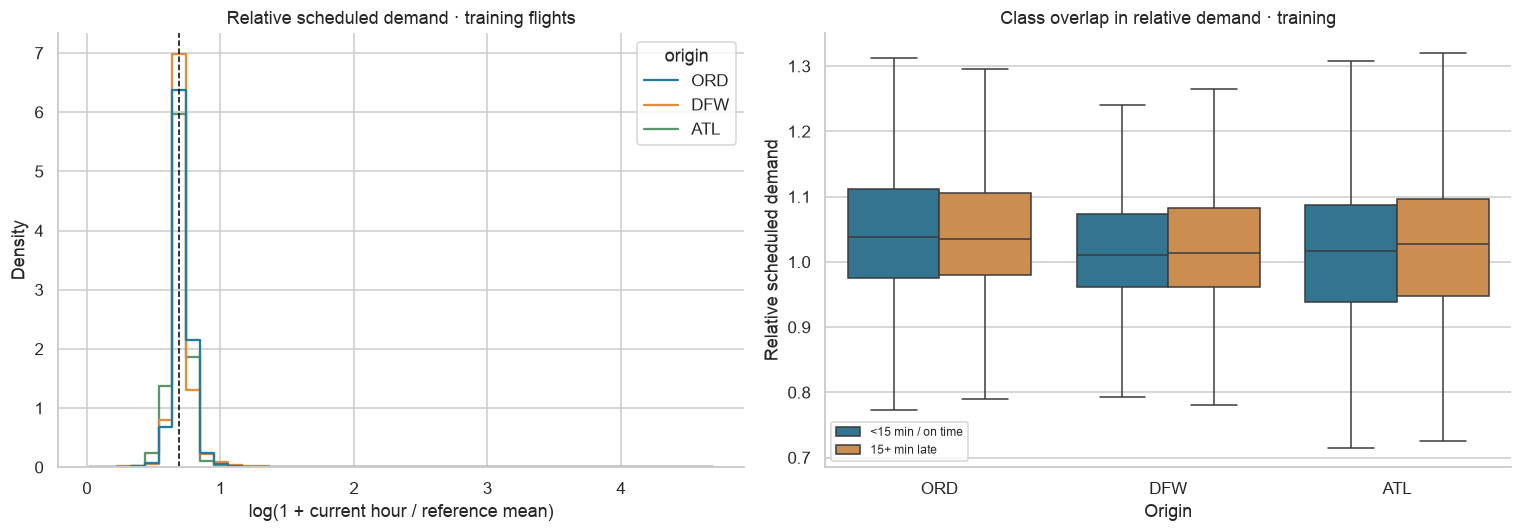

Boxplot hides fliers for readability only; no observations are removed or capped.


In [5]:
traffic_plot = development.loc[train_mask, ['origin', 'delayed_departure']].join(candidate_features[TRAFFIC_CANDIDATES + ['traffic_relative_hour']])
traffic_plot['outcome'] = traffic_plot['delayed_departure'].map({0: '<15 min / on time', 1: '15+ min late'})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=traffic_plot, x='traffic_relative_log1p', hue='origin', bins=45,
             stat='density', common_norm=False, element='step', fill=False, ax=axes[0])
axes[0].axvline(np.log(2), color='black', linestyle='--', linewidth=1)
axes[0].set(title='Relative scheduled demand · training flights', xlabel='log(1 + current hour / reference mean)')
sns.boxplot(data=traffic_plot, x='origin', y='traffic_relative_hour', hue='outcome', showfliers=False, ax=axes[1])
axes[1].set(title='Class overlap in relative demand · training', xlabel='Origin', ylabel='Relative scheduled demand')
axes[1].legend(title='', fontsize=8)
extension_plot()
print('Boxplot hides fliers for readability only; no observations are removed or capped.')


### 2. Weather × scheduled demand

Multiply log-transformed relative traffic by reported rain, reported thunder and wind speed. A continuous visibility interaction is **log(1 + relative traffic) / (1 + visibility in miles)**: lower visibility gives a larger value at the same demand. The added one mile is a fixed smoothing constant, not a tuned physical threshold.

Unknown weather stays unknown. These interactions are particularly useful hypotheses for a linear classifier; trees may already learn similar combinations. The heatmap below is descriptive training EDA, with counts and cells below 50 flights hidden. It cannot establish predictive improvement or causation.


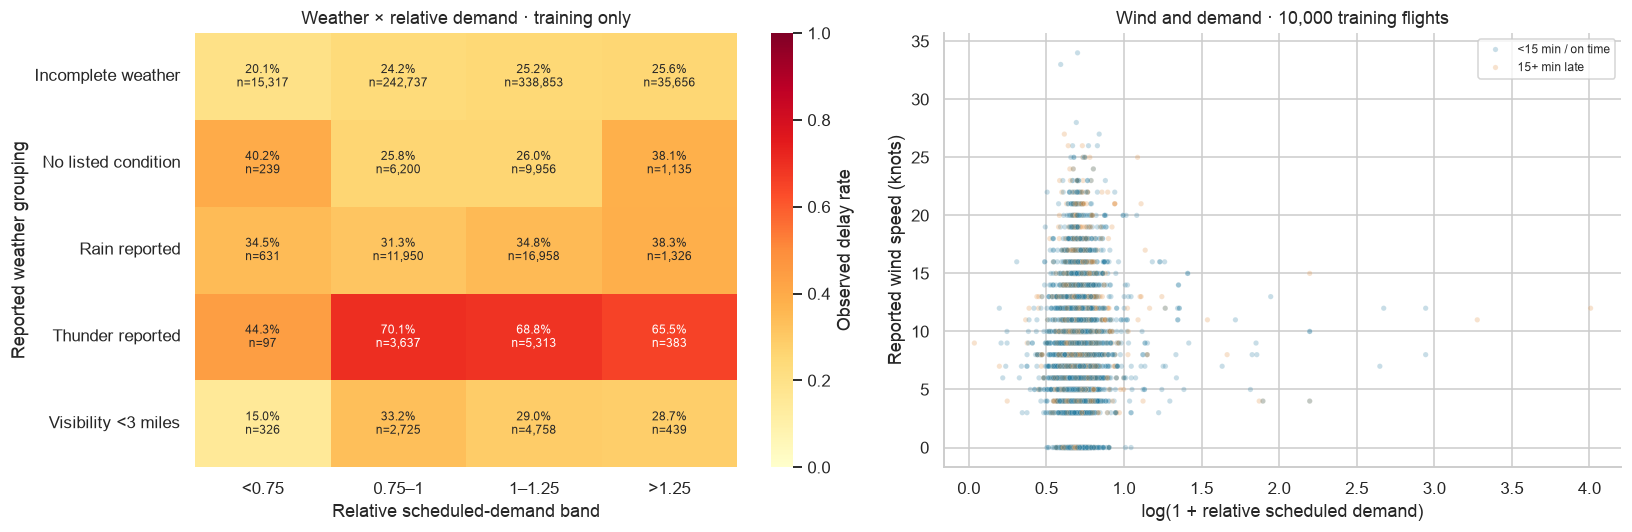

                                  flights  delay_rate
weather_group       traffic_band                     
Incomplete weather  <0.75           15317    0.201410
                    0.75–1         242737    0.241834
                    1–1.25         338853    0.252440
                    >1.25           35656    0.256282
No listed condition <0.75             239    0.401674
                    0.75–1           6200    0.257903
                    1–1.25           9956    0.260346
                    >1.25            1135    0.381498
Rain reported       <0.75             631    0.345483
                    0.75–1          11950    0.312971
                    1–1.25          16958    0.348036
                    >1.25            1326    0.383107
Thunder reported    <0.75              97    0.443299
                    0.75–1           3637    0.701127
                    1–1.25           5313    0.688312
                    >1.25             383    0.655352
Visibility <3 miles <0.75   

In [6]:
relative = candidate_features['traffic_relative_log1p']
weather_interactions = {
    'traffic_rain_interaction': relative * development['rain_reported'],
    'traffic_thunder_interaction': relative * development['thunder_reported'],
    'traffic_wind_interaction': relative * development['wind_knots'],
    'traffic_visibility_interaction': relative / (1 + development['visibility_miles']),
}
for column, values in weather_interactions.items():
    candidate_features[column] = values
WEATHER_TRAFFIC_CANDIDATES = list(weather_interactions)
weather_plot = traffic_plot.join(development.loc[train_mask, ['rain_reported', 'thunder_reported', 'visibility_miles', 'wind_knots']])
known = weather_plot[['rain_reported', 'thunder_reported', 'visibility_miles']].notna().all(axis=1)
weather_plot['weather_group'] = np.select([
    weather_plot['thunder_reported'].eq(1), weather_plot['rain_reported'].eq(1),
    weather_plot['visibility_miles'].lt(3), known],
    ['Thunder reported', 'Rain reported', 'Visibility <3 miles', 'No listed condition'], default='Incomplete weather')
weather_plot['traffic_band'] = pd.cut(weather_plot['traffic_relative_hour'],
    [-np.inf, .75, 1, 1.25, np.inf], labels=['<0.75', '0.75–1', '1–1.25', '>1.25'])
weather_by_traffic = weather_plot.groupby(['weather_group', 'traffic_band'], observed=True).agg(
    flights=('delayed_departure', 'size'), delay_rate=('delayed_departure', 'mean'))
rates = weather_by_traffic['delay_rate'].unstack('traffic_band')
counts = weather_by_traffic['flights'].unstack('traffic_band').reindex_like(rates)
labels = rates.map(lambda v: f'{v:.1%}' if pd.notna(v) else '').astype(str)
labels += counts.map(lambda v: f'\nn={int(v):,}' if pd.notna(v) else '')
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(rates, mask=counts.lt(50) | counts.isna(), annot=labels, fmt='', cmap='YlOrRd',
            vmin=0, vmax=1, annot_kws={'fontsize': 8}, ax=axes[0], cbar_kws={'label': 'Observed delay rate'})
axes[0].set(title='Weather × relative demand · training only', xlabel='Relative scheduled-demand band', ylabel='Reported weather grouping')
scatter = weather_plot.sample(min(10_000, len(weather_plot)), random_state=SEED)
sns.scatterplot(data=scatter, x='traffic_relative_log1p', y='wind_knots', hue='outcome', alpha=.25, s=12, ax=axes[1])
axes[1].set(title='Wind and demand · 10,000 training flights', xlabel='log(1 + relative scheduled demand)', ylabel='Reported wind speed (knots)')
axes[1].legend(title='', fontsize=8)
extension_plot()
extension_table(weather_by_traffic)


### 3. Shorter and longer reliability histories

Create rates, counts and no-history flags for 7-day and 42-day windows at origin, airline/origin and route level. Each window still ends seven days before cutoff, so the shorter rate does **not** describe today's disruptions. Subgroup rates use the same fixed 20-flight smoothing strength toward the origin rate **from that same window**.

The difference `7-day rate − 42-day rate` describes a recent change in earlier reliability. Sparse routes can still be noisy; counts and flags expose that uncertainty. Historical outcomes may come from an earlier development-validation flight only after the lag, as in the existing sequential simulation. No classifier is fitted on them here.


In [7]:
HISTORY_CANDIDATES = []
history_groups = {'origin': ['origin'], 'airline_origin': ['origin', 'airline'],
                  'route': ['origin', 'destination']}
earliest_context_date = context['flight_date'].min().tz_localize('UTC') + pd.Timedelta(days=1)
assert (development['prediction_cutoff_utc'] - pd.Timedelta(days=LAG_DAYS + LONG_DAYS)
        > earliest_context_date).all(), 'Incomplete outcome warm-up.'
for days in [7, LONG_DAYS]:
    for name, groups in history_groups.items():
        n, delayed, latest = past_window_totals(development, events, groups,
            'departure_outcome_event_utc', 'delayed_departure', days)
        prefix = f'history_{name}_{days}d'
        if name == 'origin':
            rate = np.divide(delayed, n, out=np.full(len(n), np.nan), where=n > 0)
        else:
            prior = candidate_features[f'history_origin_{days}d_rate'].to_numpy()
            rate = (delayed + PRIOR * prior) / (n + PRIOR)
        candidate_features[prefix + '_rate'] = rate
        candidate_features[prefix + '_n'] = n
        candidate_features[prefix + '_no_history'] = (n == 0).astype('int8')
        HISTORY_CANDIDATES += [prefix + suffix for suffix in ['_rate', '_n', '_no_history']]
        window_audit[prefix] = latest
        assert pd.Series(rate).dropna().between(0, 1).all()
for name in history_groups:
    column = f'history_{name}_7d_minus_{LONG_DAYS}d'
    candidate_features[column] = (candidate_features[f'history_{name}_7d_rate']
                                  - candidate_features[f'history_{name}_{LONG_DAYS}d_rate'])
    HISTORY_CANDIDATES.append(column)
AUDIT_ONLY = ['traffic_relative_hour', 'traffic_reference_n',
              'history_origin_7d_no_history', 'history_origin_42d_no_history']
HISTORY_CANDIDATES = [c for c in HISTORY_CANDIDATES if c not in AUDIT_ONLY]
print(f'Created 21 history columns; {len(HISTORY_CANDIDATES)} are candidate predictors.')
print('Origin no-history flags are audit-only: they are constant with the available complete warm-up.')


Created 21 history columns; 19 are candidate predictors.
Origin no-history flags are audit-only: they are constant with the available complete warm-up.


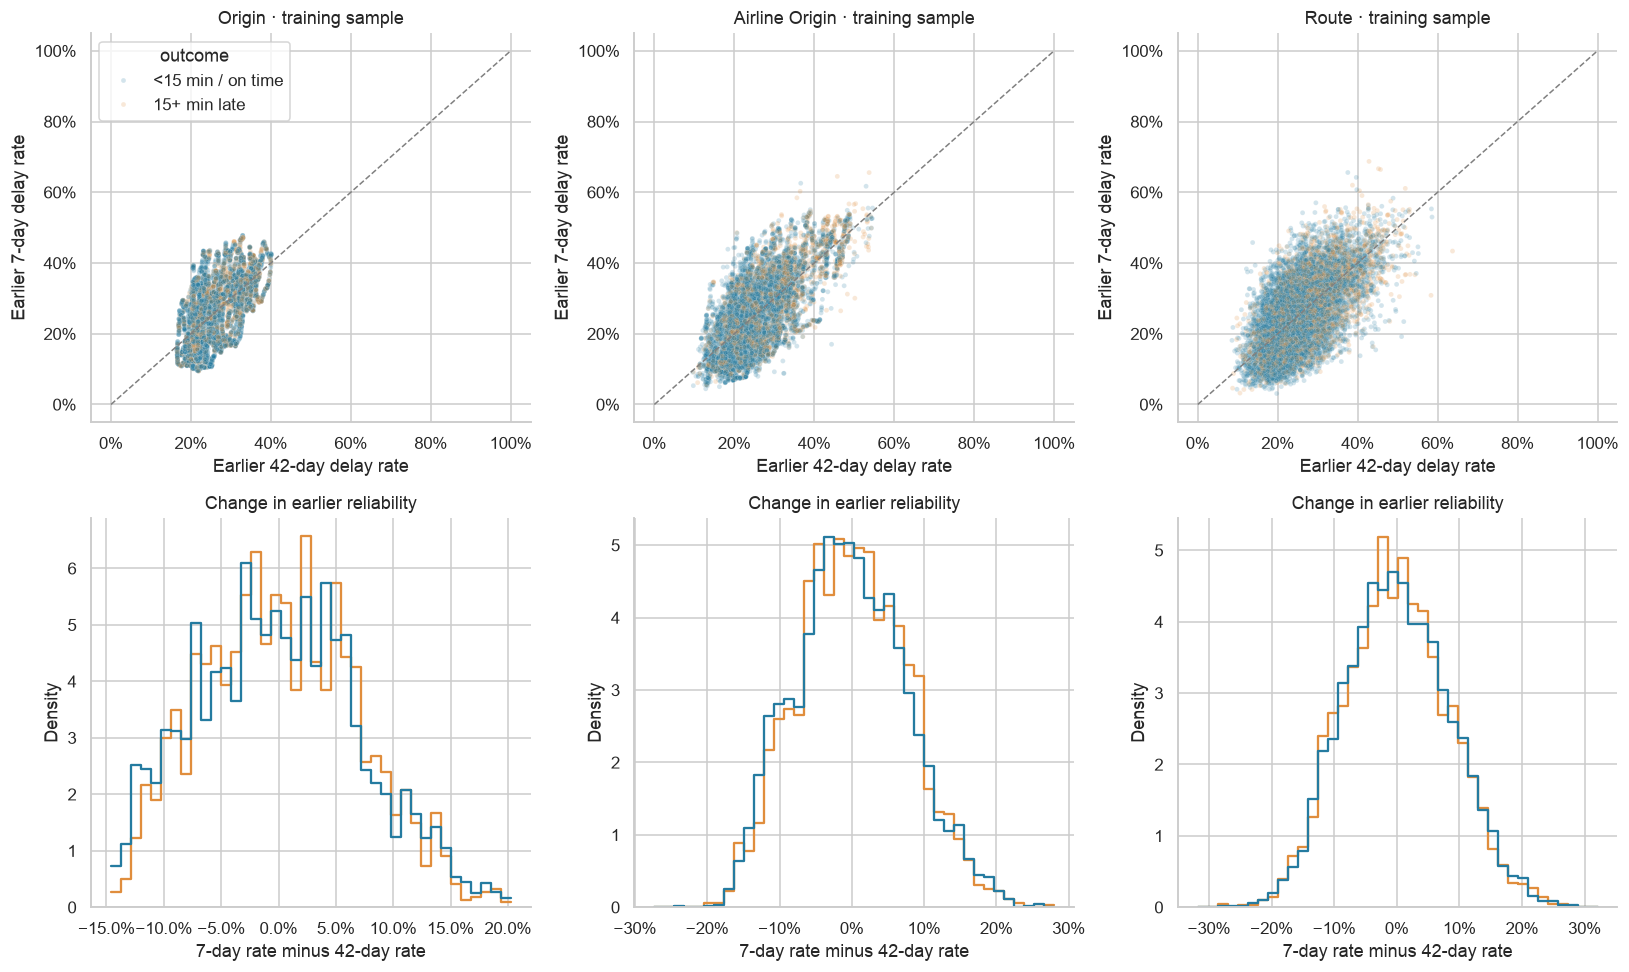

In [8]:
history_sample = candidate_features.loc[train_mask].sample(10_000, random_state=SEED)
history_sample = history_sample.join(development[['delayed_departure']])
history_sample['outcome'] = history_sample['delayed_departure'].map({0: '<15 min / on time', 1: '15+ min late'})
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for j, name in enumerate(history_groups):
    sns.scatterplot(data=history_sample, x=f'history_{name}_{LONG_DAYS}d_rate',
        y=f'history_{name}_7d_rate', hue='outcome', alpha=.2, s=10, ax=axes[0, j], legend=j == 0)
    axes[0, j].plot([0, 1], [0, 1], '--', color='grey', linewidth=1)
    axes[0, j].set(title=name.replace('_', ' ').title() + ' · training sample',
                   xlabel=f'Earlier {LONG_DAYS}-day delay rate', ylabel='Earlier 7-day delay rate')
    sns.histplot(data=history_sample, x=f'history_{name}_7d_minus_{LONG_DAYS}d', hue='outcome',
        bins=40, stat='density', common_norm=False, element='step', fill=False,
        ax=axes[1, j], legend=False)
    axes[1, j].set(title='Change in earlier reliability', xlabel=f'7-day rate minus {LONG_DAYS}-day rate')
    for ax in axes[:, j]:
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    axes[0, j].yaxis.set_major_formatter(PercentFormatter(1))
extension_plot()


### Missingness, redundancy and explicit candidate groups

Missing ratios or weather interactions remain missing; they are not filled using all development rows. Imputation, scaling and any feature selection must be fitted inside each future training fold. Keep binary flags separate from continuous scaling, as in notebook 04.

The correlation heatmap describes **predictor redundancy in training only**. A strong individual correlation is not required, and this plot does not select features. Controlled comparisons should add one group at a time to the current 66-predictor recipe, using identical flights, model settings and validation periods.

The raw traffic ratio, reference-slot count and origin no-history flags remain audit-only. Reference-slot counts and origin no-history flags are constant in the current training data; they add no separation here. Any further learned feature filtering must still be fitted separately inside each training fold.


                                                    group  training_missing_pct  training_unique
history_airline_origin_42d_n           multiscale_history              0.000000            20279
history_airline_origin_42d_no_history  multiscale_history              0.000000                2
history_airline_origin_42d_rate        multiscale_history              0.000000           406308
history_airline_origin_7d_minus_42d    multiscale_history              0.000000           444245
history_airline_origin_7d_n            multiscale_history              0.000000             4642
history_airline_origin_7d_no_history   multiscale_history              0.000000                2
history_airline_origin_7d_rate         multiscale_history              0.000000           397305
history_origin_42d_n                   multiscale_history              0.000000            11815
history_origin_42d_no_history                  audit_only              0.000000                1
history_origin_42d_rate       

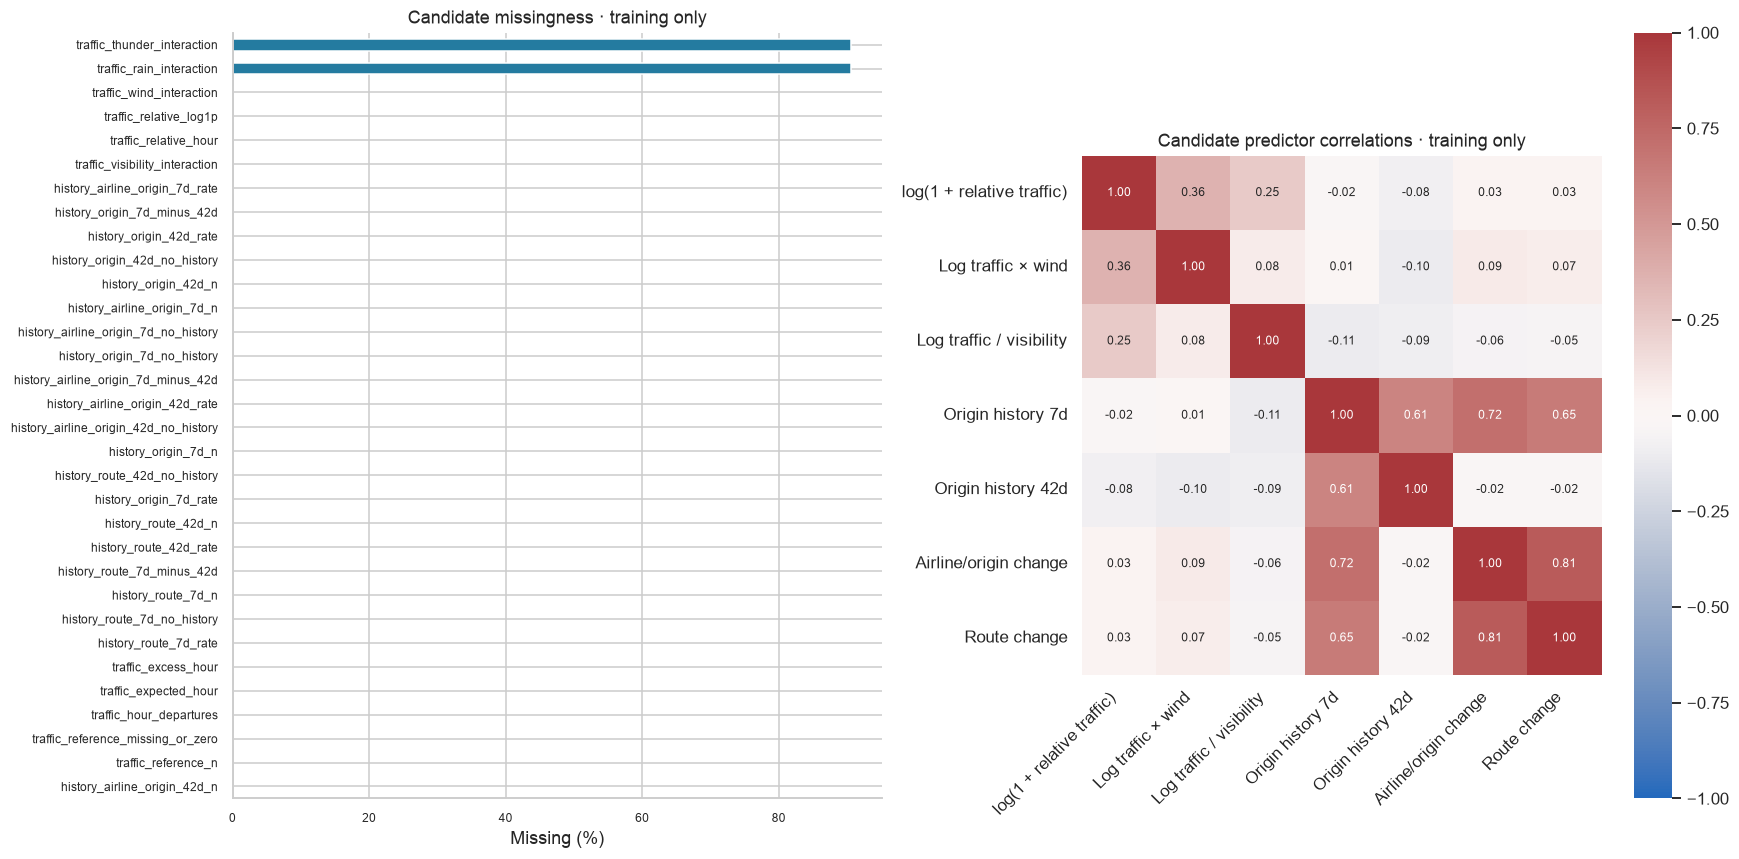

In [9]:
CANDIDATE_GROUPS = {'relative_traffic': TRAFFIC_CANDIDATES,
    'weather_traffic': WEATHER_TRAFFIC_CANDIDATES, 'multiscale_history': HISTORY_CANDIDATES}
NEW_FEATURES = [c for columns in CANDIDATE_GROUPS.values() for c in columns]
candidate_profile = pd.DataFrame({
    'group': {c: group for group, columns in CANDIDATE_GROUPS.items() for c in columns},
    'training_missing_pct': 100 * candidate_features.loc[train_mask].isna().mean(),
    'training_unique': candidate_features.loc[train_mask].nunique()})
candidate_profile.loc[AUDIT_ONLY, 'group'] = 'audit_only'
extension_table(candidate_profile)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
candidate_profile['training_missing_pct'].sort_values().plot.barh(ax=axes[0], fontsize=8)
axes[0].set(title='Candidate missingness · training only', xlabel='Missing (%)', ylabel='')
correlation_columns = ['traffic_relative_log1p', 'traffic_wind_interaction', 'traffic_visibility_interaction',
    'history_origin_7d_rate', 'history_origin_42d_rate', 'history_airline_origin_7d_minus_42d',
    'history_route_7d_minus_42d']
correlation_labels = ['log(1 + relative traffic)', 'Log traffic × wind', 'Log traffic / visibility',
    'Origin history 7d', 'Origin history 42d', 'Airline/origin change', 'Route change']
corr = candidate_features.loc[train_mask, correlation_columns].corr()
corr.index = corr.columns = correlation_labels
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, square=True,
            annot_kws={'fontsize': 8}, ax=axes[1])
axes[1].set_title('Candidate predictor correlations · training only')
plt.setp(axes[1].get_xticklabels(), rotation=45, ha='right')
extension_plot()


### In-memory handoff and final checks

`candidate_feature_table` contains every eligible 2025 development flight with the current 66 predictors and the new candidates, plus four audit-only fields. `CANDIDATE_FEATURE_SETS` defines separate comparisons. The **weather–traffic group requires relative traffic**, so its comparison includes both; the relative-traffic-only comparison isolates that dependency. Labels, dates and audit fields remain outside the predictor lists.

This appendix does not alter sampling. Existing membership flags are retained; a future experiment should reuse the shared IDs from the frozen 20k/40k study. It also does not modify notebook 04's frozen experiment or evaluate either 2026 quarter. New model and threshold choices need development validation, followed by an unexamined period for an unbiased confirmation.


In [10]:
assert len(NEW_FEATURES) == len(set(NEW_FEATURES)) == 28
assert not set(NEW_FEATURES).intersection(development.columns)
assert development['flight_id'].equals(original_ids)
assert candidate_features.index.equals(development.index)
assert not np.isinf(candidate_features.to_numpy(dtype=float)).any()
for feature, source in [('traffic_rain_interaction', 'rain_reported'),
                        ('traffic_thunder_interaction', 'thunder_reported'),
                        ('traffic_wind_interaction', 'wind_knots'),
                        ('traffic_visibility_interaction', 'visibility_miles')]:
    assert candidate_features.loc[development[source].isna(), feature].isna().all()

candidate_feature_table = pd.concat([development, candidate_features], axis=1)
CANDIDATE_FEATURE_SETS = {'current_66': CURRENT_B,
    'current_plus_traffic': CURRENT_B + TRAFFIC_CANDIDATES,
    'current_plus_traffic_weather': CURRENT_B + TRAFFIC_CANDIDATES + WEATHER_TRAFFIC_CANDIDATES,
    'current_plus_history': CURRENT_B + HISTORY_CANDIDATES,
    'current_plus_all': CURRENT_B + NEW_FEATURES}
for columns in CANDIDATE_FEATURE_SETS.values():
    assert len(columns) == len(set(columns))
    assert set(columns).issubset(candidate_feature_table.columns)
    assert not {'delayed_departure', 'flight_id', 'flight_number', 'departure_outcome_event_utc',
                'prediction_cutoff_utc', 'tail_number', 'Tail_Number'}.intersection(columns)
    assert not candidate_feature_table[columns].select_dtypes(include=['datetime', 'datetimetz']).shape[1]
assert all(extension_sha(ROOT / p) == checksum for p, checksum in protected_before.items())
extension_table(pd.DataFrame({'predictors': {name: len(columns) for name, columns in CANDIDATE_FEATURE_SETS.items()}}))
print(f'{len(candidate_feature_table):,} development flights retained; no 2026 rows, no saved datasets, no fitted classifiers.')
print('Next: compare candidate groups on chronological 2025 validation. F1 improvement is not yet established.')


                              predictors
current_66                            66
current_plus_traffic                  71
current_plus_traffic_weather          75
current_plus_history                  85
current_plus_all                      94
938,417 development flights retained; no 2026 rows, no saved datasets, no fitted classifiers.
Next: compare candidate groups on chronological 2025 validation. F1 improvement is not yet established.


### Reading these results

The appended section ran successfully in a fresh Python 3.13 kernel: **10 code cells and four figures**, with no errors or warnings. It retained **938,417 development flights** (698,670 training; 239,747 validation). The original 38 cells and their saved outputs remain intact.

- **28 candidate predictors** are available alongside the existing 66. Four other created columns are audit-only. Candidate comparisons contain 66 / 71 / 75 / 85 / 94 predictors; they have not yet been trained.
- Relative traffic is usually near its reference mean, and the training outcome boxplots overlap substantially. The raw ratio reaches 108 when reference activity is tiny; `log(1 + ratio)` reduces that leverage without deleting or capping flights. There are 94 development flights with a zero reference mean; their ratios stay unknown with a separate flag.
- Rain/thunder interactions are **90.59% missing in training**, following the conservative existing condition-code policy. Wind and visibility interactions are much more complete. Unknown codes have not been relabelled as dry weather.
- The 7-day versus 42-day histories show changing earlier reliability, but their class distributions overlap. Airline/origin and route changes correlate about **0.81** in training, so they may contain redundant information. Keep only what helps later validation.
- All windows preserve the seven-day lag. Independent direct-mask checks verified **144 history rates/counts and 48 traffic calculations**. Both original datasets, their shared manifest, and the fitted-model selection and bundle checksums are unchanged.

**No F1 improvement has been established by this appendix.** The next modelling experiment must compare groups on identical flights with chronological 2025 validation and fit all imputation/scaling/learned selection within each training fold. A new unexamined period is needed for unbiased final confirmation; both 2026 test quarters are already exposed. For Tableau, claims about added predictive value must come from that model comparison, not these descriptive plots.


## Broader feature experiments inspired by other projects

Run the preceding **Additional feature engineering** appendix first in the same kernel. This section deliberately tries plausible candidates **without filtering them by individual target correlation**. All 938,417 eligible 2025 development flights remain available; 2026 outcome labels are not used.

| Inspiration | What we try here |
|---|---|
| [Serena Fang's departure-delay project](https://github.com/Serena-Fang/Machine-Learning-Project-Flight-Delay-Prediction) retained weakly correlated day variables as categories and tried distance/time bins. | Day-of-month/hour categories, distance bands, route and airline–airport combinations. |
| [Stanford CS229 project](https://cs229.stanford.edu/proj2016/report/DuperierSauvestreLeaf-ModelingFlightDelays-report.pdf) used holidays, squared inputs and scheduled arrival/departure counts. Its target was arrival delay at departure time. | Holiday proximity, nonlinear weather terms, schedule waves and aggregate scheduled incoming traffic. Its headline results are not our benchmark. |
| [Kim and Park](https://link.springer.com/article/10.1186/s40537-023-00867-5) investigated richer weather, including pressure. Their weather-delay populations differ from ours. | Altimeter setting and changes in already available METAR observations. Altimeter setting is not the same measurement as sea-level pressure. |
| Our additional hypotheses | Route geometry, airline schedule concentration and time-of-day-conditioned earlier reliability. |

The following controlled **development screening** fits familiar models; it does not replace notebooks 03–05 or their frozen results. Group selection uses 2025 outcomes, so these results will need an unexamined confirmation period before any final performance claim. No extra processed datasets or split CSVs are written.


In [11]:
assert 'candidate_feature_table' in globals(), 'Run the preceding Additional feature engineering appendix first.'
from pandas.tseries.holiday import USFederalHolidayCalendar
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score, confusion_matrix
from datetime import datetime, timezone
from time import perf_counter

broad_features = pd.DataFrame(index=development.index)
BROAD_GROUPS = {}
BROAD_BINARY = []
broad_inputs_before = dict(protected_before)
for relative in ['models/flight_delay_models.joblib', 'reports/model_selection.json',
                 'reports/improvements/test_results.json', 'tableau/exports/improved/export_manifest.json']:
    broad_inputs_before[relative] = extension_sha(ROOT / relative)
BROAD_SEED = 42
print('Feature groups will be compared on identical, natural-proportion 2025 flight samples.')


Feature groups will be compared on identical, natural-proportion 2025 flight samples.


### Calendar, holidays and categorical combinations

Use the recurring U.S. federal-holiday calendar, padded on both sides of 2025. Holiday windows are a demand hypothesis, not a count of passengers. The three-day flag is fixed before fitting. The [OPM calendar](https://www.opm.gov/policy-data-oversight/pay-leave/federal-holidays/#url=2025) supplies the definition; school/local holidays and exceptional closures are not included.

Categorical combinations let a linear model learn route- or airline/airport-specific effects. All category encoding will be fitted on each training fold, with unseen categories handled explicitly.


In [12]:
dates = development['flight_date'].dt.normalize()
holidays = USFederalHolidayCalendar().holidays('2024-01-01', '2026-12-31')
day_values = dates.to_numpy(dtype='datetime64[D]')
holiday_values = holidays.to_numpy(dtype='datetime64[D]')
before = np.searchsorted(holiday_values, day_values, side='right') - 1
after = np.searchsorted(holiday_values, day_values, side='left')
calendar_values = {
    'calendar_weekend': development['weekday'].ge(5).astype('int8'),
    'calendar_weekday_sin': np.sin(2*np.pi*development['weekday']/7),
    'calendar_weekday_cos': np.cos(2*np.pi*development['weekday']/7),
    'calendar_year_day_sin': np.sin(2*np.pi*(dates.dt.dayofyear-1)/365.2425),
    'calendar_year_day_cos': np.cos(2*np.pi*(dates.dt.dayofyear-1)/365.2425),
    'calendar_month_start': dates.dt.is_month_start.astype('int8'),
    'calendar_month_end': dates.dt.is_month_end.astype('int8'),
    'days_since_federal_holiday': (day_values-holiday_values[before]).astype(int),
    'days_until_federal_holiday': (holiday_values[after]-day_values).astype(int),
    'calendar_federal_holiday': dates.isin(holidays).astype('int8'),
}
calendar_values['calendar_holiday_within3d'] = (np.minimum(
    calendar_values['days_since_federal_holiday'], calendar_values['days_until_federal_holiday']) <= 3).astype('int8')
for c, values in calendar_values.items():
    broad_features[c] = values
BROAD_GROUPS['calendar_holidays'] = list(calendar_values)
BROAD_BINARY += ['calendar_weekend', 'calendar_month_start', 'calendar_month_end',
                 'calendar_federal_holiday', 'calendar_holiday_within3d']
period = (development['scheduled_departure_minutes']//240).astype('string')
category_values = {
    'day_of_month_cat': dates.dt.day.astype('string'),
    'departure_hour_cat': (development['scheduled_departure_minutes']//60).astype('string'),
    'distance_band_cat': pd.cut(development['distance_miles'], [0,500,1000,np.inf],
                                labels=['short_0_500', 'medium_500_1000', 'long_1000_plus']).astype('string'),
    'route_cat': development['origin'] + '>' + development['destination'],
    'airline_origin_cat': development['airline'] + '@' + development['origin'],
    'origin_period_cat': development['origin'] + '@' + period,
}
for c, values in category_values.items():
    broad_features[c] = values
BROAD_GROUPS['categories_combinations'] = list(category_values)
print('2025 recurring federal holidays:', holidays[holidays.year == 2025].strftime('%Y-%m-%d').tolist())


2025 recurring federal holidays: ['2025-01-01', '2025-01-20', '2025-02-17', '2025-05-26', '2025-06-19', '2025-07-04', '2025-09-01', '2025-10-13', '2025-11-11', '2025-11-27', '2025-12-25']


### Route geometry and schedule structure

Use existing raw airport coordinates/elevation, not current operational/closure status. This is important for a historical project: the reference catalog may describe an airport differently today. Route direction is a geographic proxy, not runway heading or measured en-route weather. Duration per distance is scheduled time, not actual speed or aircraft performance.

For schedule demand, use all scoped schedules, including later cancellations. Day counts, shares, first departures and gaps are based on the airport's **local scheduled day**. A first airline/route departure is not necessarily an aircraft's first flight. The first two January 2026 schedule days supply boundary context only; no outcome columns are loaded from them. Archived schedule availability remains an assumption.


In [13]:
airports = pd.read_csv(ROOT / 'data/raw/reference/airports/airports.csv', dtype='string')
needed_airports = set(development['origin']) | set(development['destination'])
airports = airports.loc[airports['iata_code'].isin(needed_airports)].set_index('iata_code')
assert airports.index.is_unique, 'Ambiguous airport identifiers require review.'
coords = {}
for name in ['latitude_deg', 'longitude_deg', 'elevation_ft']:
    values = pd.to_numeric(airports[name], errors='coerce')
    coords['origin_'+name] = development['origin'].map(values)
    coords['destination_'+name] = development['destination'].map(values)
lat1, lon1, lat2, lon2 = [np.deg2rad(coords[k]) for k in [
    'origin_latitude_deg', 'origin_longitude_deg', 'destination_latitude_deg', 'destination_longitude_deg']]
dlon = lon2-lon1
angle = np.arctan2(np.sin(dlon)*np.cos(lat2),
                   np.cos(lat1)*np.sin(lat2)-np.sin(lat1)*np.cos(lat2)*np.cos(dlon))
haversine = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
great_circle = 3958.7613 * 2 * np.arcsin(np.sqrt(haversine.clip(0,1)))
route_values = {
    'route_direction_east': np.sin(angle).where(great_circle.gt(0)),
    'route_direction_north': np.cos(angle).where(great_circle.gt(0)),
    'route_great_circle_miles': great_circle,
    'route_published_distance_ratio': development['distance_miles']/great_circle.where(great_circle.gt(0)),
    'destination_latitude': coords['destination_latitude_deg'],
    'destination_longitude': coords['destination_longitude_deg'],
    'destination_elevation_ft': coords['destination_elevation_ft'],
    'scheduled_minutes_per100miles': 100*development['scheduled_duration_minutes']/development['distance_miles'].where(development['distance_miles'].gt(0)),
}
for c, values in route_values.items():
    broad_features[c] = values
BROAD_GROUPS['route_geometry'] = list(route_values)

schedule = pd.read_parquet(ROOT / 'data/processed/flights_clean.parquet', columns=[
    'flight_id','flight_date','origin','airline','destination','scheduled_departure_utc'],
    filters=[('flight_date','<',pd.Timestamp('2026-01-03'))])
schedule['local_day'] = pd.NaT
for origin, zone in zones.items():
    mask = schedule['origin'].eq(origin)
    schedule.loc[mask,'local_day'] = schedule.loc[mask,'scheduled_departure_utc'].dt.tz_convert(zone).dt.tz_localize(None).dt.normalize().to_numpy()
day_groups = ['origin','local_day']
airline_groups = day_groups+['airline']
route_groups = airline_groups+['destination']
schedule['origin_day_flights'] = schedule.groupby(day_groups,observed=True)['flight_id'].transform('size')
schedule['airline_origin_day_flights'] = schedule.groupby(airline_groups,observed=True)['flight_id'].transform('size')
schedule['airline_route_day_flights'] = schedule.groupby(route_groups,observed=True)['flight_id'].transform('size')
schedule['airline_origin_day_share'] = schedule['airline_origin_day_flights']/schedule['origin_day_flights']
schedule['airline_route_day_share'] = schedule['airline_route_day_flights']/schedule['origin_day_flights']
rank = schedule.groupby(day_groups,observed=True)['scheduled_departure_utc'].rank(method='min')-1
schedule['origin_day_schedule_progress'] = rank/(schedule['origin_day_flights']-1).clip(lower=1)
first = schedule.groupby(route_groups,observed=True)['scheduled_departure_utc'].transform('min')
schedule['airline_route_first_departure_flag'] = schedule['scheduled_departure_utc'].eq(first).astype('int8')
schedule['minutes_since_airline_route_first'] = (schedule['scheduled_departure_utc']-first).dt.total_seconds()/60
unique_times = schedule[route_groups+['scheduled_departure_utc']].drop_duplicates().sort_values('scheduled_departure_utc')
unique_times['prior_same_route_schedule_gap_min'] = unique_times.groupby(route_groups,observed=True)['scheduled_departure_utc'].diff().dt.total_seconds()/60
schedule = schedule.merge(unique_times,on=route_groups+['scheduled_departure_utc'],validate='many_to_one',how='left')
structure = ['origin_day_flights','airline_origin_day_flights','airline_route_day_flights',
    'airline_origin_day_share','airline_route_day_share','origin_day_schedule_progress',
    'airline_route_first_departure_flag','minutes_since_airline_route_first','prior_same_route_schedule_gap_min']
lookup = schedule.set_index('flight_id')
assert lookup.index.is_unique
for c in structure:
    broad_features[c] = development['flight_id'].map(lookup[c])
BROAD_GROUPS['schedule_structure'] = structure
BROAD_BINARY += ['airline_route_first_departure_flag']


In [14]:
traffic_extra = {}
for name, lower, upper in [('departures_prior15m',-15,0),('departures_next15m',0,15),
                          ('departures_next60m',0,60),('departures_prior120m',-120,0)]:
    counts = np.zeros(len(development),dtype='int32')
    for origin in zones:
        positions = np.flatnonzero(development['origin'].eq(origin).to_numpy())
        times = schedule.loc[schedule['origin'].eq(origin),'scheduled_departure_utc'].sort_values().array.asi8
        query = development.iloc[positions]['scheduled_departure_utc'].array.asi8
        counts[positions] = (np.searchsorted(times,query+pd.Timedelta(minutes=upper).value,side='left')
            - np.searchsorted(times,query+pd.Timedelta(minutes=lower).value,side='left') - (lower==0))
    assert (counts>=0).all()
    traffic_extra[name] = counts
traffic_extra['departure_bank_concentration'] = traffic_extra['departures_prior15m']/development['airport_scheduled_departures_prior_60m'].clip(lower=1)
for c, values in traffic_extra.items():
    broad_features[c] = values
BROAD_GROUPS['departure_waves'] = list(traffic_extra)


### Incoming scheduled traffic: source audit before using it

Read only schedule columns from December 2024, all 2025 and January 2026 national BTS raw files. Select flights scheduled to arrive at ATL/ORD/DFW. Every incoming schedule is retained, including later cancellations; no incoming delay or cancellation outcome is read.

The user approved using **published arrival clock time**, inferring its date from scheduled departure plus scheduled duration and flagging disagreements. Origin station timezones are joined through raw IATA/ICAO metadata. PBI uses America/New_York; STT/STX use America/St_Thomas, correcting the station catalog's inappropriate Bermuda daylight-saving rule. [IANA timezone definitions](https://data.iana.org/time-zones/tzdb/northamerica) and [links](https://data.iana.org/time-zones/tzdb/backward) define these regions.

For repeated daylight-saving clock hours, test both UTC interpretations and select the one whose inferred duration best matches the raw schedule. Likewise choose the closest plausible arrival date. Unresolved equal-best UTC times or a discrepancy of 12 hours or more stop for review. Smaller clock/duration discrepancies are flagged, not used to drop schedules. Query-level discrepancy counts are audit-only.


In [15]:
station_zones = {}
for path in (ROOT/'data/raw/weather/stations').glob('*.geojson'):
    for feature in json.loads(path.read_text())['features']:
        item = feature['properties']
        if item.get('tzname'):
            station_zones[item['sid']] = item['tzname']
reference_airports = pd.read_csv(ROOT/'data/raw/reference/airports/airports.csv',dtype='string')
origin_zones = {}
for _, airport in reference_airports.loc[reference_airports['iata_code'].notna()].iterrows():
    options = {station_zones[key] for c in ['iata_code','icao_code','gps_code'] if pd.notna(airport[c])
               for key in [airport[c],airport[c][1:] if airport[c].startswith('K') else airport[c]] if key in station_zones}
    if len(options)==1:
        origin_zones[airport['iata_code']] = options.pop()
origin_zones.update({'PBI':'America/New_York','STT':'America/St_Thomas','STX':'America/St_Thomas'})
arrival_paths = [ROOT/'data/raw/flights/bts/2024_context/csv/2024_12.csv']
arrival_paths += sorted((ROOT/'data/raw/flights/bts/2025/csv').glob('*.csv'))
arrival_paths += [ROOT/'data/raw/flights/bts/2026/csv/2026_01.csv']
incoming_parts, arrival_audit = [], []
for path in arrival_paths:
    raw = pd.read_csv(path,usecols=['FlightDate','Origin','Dest','CRSDepTime','CRSArrTime','CRSElapsedTime'])
    raw = raw.loc[raw['Dest'].isin(zones)].copy()
    raw['origin_zone'] = raw['Origin'].map(origin_zones)
    assert raw['origin_zone'].notna().all(), raw.loc[raw['origin_zone'].isna(),'Origin'].unique()
    dep, arr, duration = [pd.to_numeric(raw[c],errors='coerce') for c in ['CRSDepTime','CRSArrTime','CRSElapsedTime']]
    for clock in [dep,arr]:
        assert ((clock.mod(1)==0)&clock.between(0,2400)&clock.mod(100).lt(60)).all()
    assert duration.gt(0).all()
    naive = pd.to_datetime(raw['FlightDate'])+pd.to_timedelta(dep//100*60+dep%100,unit='m')
    departure_options = []
    for ambiguous in [True,False]:
        utc = pd.Series(pd.NaT,index=raw.index,dtype='datetime64[ns, UTC]')
        for zone, positions in raw.groupby('origin_zone').groups.items():
            utc.loc[positions] = naive.loc[positions].dt.tz_localize(zone,ambiguous=ambiguous,
                nonexistent='NaT').dt.tz_convert('UTC').astype('datetime64[ns, UTC]')
        assert utc.notna().all(), 'A nonexistent departure clock requires review.'
        departure_options.append(utc)
    best = pd.Series(pd.NaT,index=raw.index,dtype='datetime64[ns, UTC]')
    error = pd.Series(np.inf,index=raw.index)
    unresolved = pd.Series(False,index=raw.index)
    for departure in departure_options:
        estimate = departure+pd.to_timedelta(duration,unit='m')
        for origin, zone in zones.items():
            positions = raw['Dest'].eq(origin)
            local_day = estimate.loc[positions].dt.tz_convert(zone).dt.tz_localize(None).dt.normalize()
            for shift in [-1,0,1]:
                local_clock = local_day+pd.Timedelta(days=shift)+pd.to_timedelta((arr.loc[positions]//100*60+arr.loc[positions]%100).mod(1440),unit='m')
                for ambiguous in [True,False]:
                    candidate = local_clock.dt.tz_localize(zone,ambiguous=ambiguous,nonexistent='NaT').dt.tz_convert('UTC').astype('datetime64[ns, UTC]')
                    delta = (candidate-estimate.loc[positions]).abs().dt.total_seconds()/60
                    improve = delta.lt(error.loc[positions])
                    ties = delta.eq(error.loc[positions]) & candidate.ne(best.loc[positions]) & candidate.notna()
                    unresolved.loc[ties.index[ties]] = True
                    ix = improve.index[improve]
                    best.loc[ix], error.loc[ix], unresolved.loc[ix] = candidate.loc[ix], delta.loc[ix], False
    assert best.notna().all() and error.lt(720).all() and not unresolved.any(), 'Unresolved arrival-date ambiguity requires review.'
    flag = error.gt(0).astype('int8')
    incoming_parts.append(pd.DataFrame({'origin':raw['Dest'],'arrival_utc':best,'schedule_clock_disagreement':flag}))
    arrival_audit.append({'source':path.relative_to(ROOT).as_posix(),'rows':len(raw),
        'flagged_clock_duration_disagreements':int(flag.sum()),'max_discrepancy_minutes':float(error.max())})
    print(path.stem, 'incoming schedules:',len(raw),'flagged:',int(flag.sum()),flush=True)
incoming = pd.concat(incoming_parts,ignore_index=True)
arrival_counts = {}
arrival_disagreement_audit = np.zeros(len(development),dtype='int32')
for name, lower, upper in [('arrivals_prior60m',-60,0),('arrivals_next60m',0,60)]:
    counts = np.zeros(len(development),dtype='int32')
    for origin in zones:
        positions = np.flatnonzero(development['origin'].eq(origin).to_numpy())
        block = incoming.loc[incoming['origin'].eq(origin)].sort_values('arrival_utc')
        times = block['arrival_utc'].array.asi8
        query = development.iloc[positions]['scheduled_departure_utc'].array.asi8
        left = np.searchsorted(times,query+pd.Timedelta(minutes=lower).value,side='left')
        right = np.searchsorted(times,query+pd.Timedelta(minutes=upper).value,side='left')
        counts[positions] = right-left
        if lower<0:
            flagged = np.r_[0,block['schedule_clock_disagreement'].cumsum().to_numpy()]
            arrival_disagreement_audit[positions] = flagged[right]-flagged[left]
    arrival_counts[name] = counts
arrival_counts['scheduled_movements_prior60m'] = arrival_counts['arrivals_prior60m']+development['airport_scheduled_departures_prior_60m']
arrival_counts['arrival_departure_balance'] = (arrival_counts['arrivals_prior60m']-development['airport_scheduled_departures_prior_60m'])/(1+arrival_counts['scheduled_movements_prior60m'])
for c, values in arrival_counts.items():
    broad_features[c] = values
BROAD_GROUPS['scheduled_arrivals'] = list(arrival_counts)
print('Development flights whose prior-hour arrivals include a flagged schedule:',int((arrival_disagreement_audit>0).sum()))


2024_12 incoming schedules: 77474 flagged: 4


2025_01 incoming schedules: 70647 flagged: 3


2025_02 incoming schedules: 65477 flagged: 3


2025_03 incoming schedules: 78123 flagged: 4


2025_04 incoming schedules: 77328 flagged: 2


...

2025_10 incoming schedules: 85819 flagged: 0


2025_11 incoming schedules: 79622 flagged: 2


2025_12 incoming schedules: 79322 flagged: 1


2026_01 incoming schedules: 73938 flagged: 0


Development flights whose prior-hour arrivals include a flagged schedule: 892


### Pressure, variable wind and nonlinear weather representations

Parse altimeter setting only from the METAR body, before RMK: A2992 means 29.92 inHg. [NWS decoding](https://aviationweather.gov/help/data/) distinguishes this from sea-level pressure. Multiple pressure groups or missing groups stay unknown. Changes/ranges use reports in the three hours ending at the matched report; no later report is used and no interpolation reaches forward.

Try squared temperature/wind, log precipitation/ceiling and reciprocal visibility. These are fixed transformations, not features picked because of a large correlation. Zero ceilings or precipitation retain their original meaning; absent gusts or ceilings remain unknown. A positive gust excess is a derived definition, not capping the original observations.


In [16]:
weather_broad, _ = load_weather(ROOT,[2025],CONFIG['weather_quality']['excluded_station_times'])
body = weather_broad['metar'].str.split(r'\s+RMK(?:\s|$)',n=1,regex=True).str[0]
groups = body.str.findall(r'(?<!\S)A(\d{4})(?=\s|=|$)')
weather_broad['altimeter_inhg'] = pd.to_numeric(groups.str[0],errors='coerce').div(100).where(groups.str.len().eq(1))
wind_group = body.str.extract(r'(?<!\S)((?:\d{3}|VRB)\d{2,3}(?:G\d{2,3})?KT)(?=\s|=|$)',expand=False)
weather_broad['variable_wind_flag'] = wind_group.str.startswith('VRB').astype(float).where(wind_group.notna())
weather_broad['gust_excess_knots'] = (weather_broad['gust_knots']-weather_broad['wind_knots']).clip(lower=0)
pressure_blocks = []
for _, block in weather_broad.groupby('origin',observed=True):
    block = block.sort_values('weather_observed_utc').set_index('weather_observed_utc')
    rolling = block['altimeter_inhg'].rolling('3h',closed='both')
    first = rolling.apply(lambda a:a[np.isfinite(a)][0] if np.isfinite(a).any() else np.nan,raw=True)
    block['altimeter_change3h_inhg'] = block['altimeter_inhg']-first
    block['altimeter_range3h_inhg'] = rolling.max()-rolling.min()
    pressure_blocks.append(block.reset_index())
weather_broad = pd.concat(pressure_blocks,ignore_index=True)
pressure_columns = ['altimeter_inhg','altimeter_change3h_inhg','altimeter_range3h_inhg',
                    'variable_wind_flag','gust_excess_knots']
matched = development[['origin','weather_observed_utc']].merge(
    weather_broad[['origin','weather_observed_utc']+pressure_columns],
    how='left',on=['origin','weather_observed_utc'],validate='many_to_one')
assert len(matched)==len(development)
for c in pressure_columns:
    broad_features[c] = matched[c].to_numpy()
broad_features['altimeter_missing_flag'] = broad_features['altimeter_inhg'].isna().astype('int8')
BROAD_GROUPS['pressure_wind'] = pressure_columns+['altimeter_missing_flag']
BROAD_BINARY += ['variable_wind_flag','altimeter_missing_flag']
shape_values = {
    'temperature_centered_square': ((development['temperature_f']-32)/10)**2,
    'wind_square': development['wind_knots']**2,
    'dewpoint_spread_square': development['dewpoint_spread_f']**2,
    'precip_log1p': np.log1p(development['precip_inches']),
    'ceiling_log1p': np.log1p(development['ceiling_ft']),
    'visibility_inverse': 1/(1+development['visibility_miles']),
}
for c, values in shape_values.items():
    broad_features[c] = values
BROAD_GROUPS['nonlinear_weather'] = list(shape_values)

assert broad_features['altimeter_inhg'].notna().any(), 'No altimeter values parsed; review the source format.'


### Earlier reliability conditioned on departure period

Compute 28-day history for origin/period, airline/origin/period and route/period, using six fixed four-hour local departure periods. Every outcome is at least seven days older than cutoff. Subgroup rates use a fixed 20-flight smoothing strength toward the matching origin/period rate. This tests a time-conditioned target-encoding idea without encoding any flight using its own or a later label.


In [17]:
conditional_query = development[['origin','airline','destination','prediction_cutoff_utc']].copy()
conditional_query['departure_period'] = development['scheduled_departure_minutes']//240
conditional_events = events.copy()
conditional_events['departure_period'] = conditional_events['scheduled_departure_minutes']//240
conditioned_columns = []
conditional_latest = {}
for name, keys in [('origin_period',['origin','departure_period']),
                   ('airline_origin_period',['origin','airline','departure_period']),
                   ('route_period',['origin','destination','departure_period'])]:
    count, delayed, latest = past_window_totals(conditional_query,conditional_events,keys,
        'departure_outcome_event_utc','delayed_departure',28)
    if name=='origin_period':
        rate = np.divide(delayed,count,out=np.full(len(count),np.nan),where=count>0)
    else:
        prior = broad_features['conditioned_origin_period_rate'].to_numpy()
        rate = (delayed+20*prior)/(count+20)
    prefix = 'conditioned_'+name
    for suffix, values in [('_rate',rate),('_n',count),('_no_history',(count==0).astype('int8'))]:
        broad_features[prefix+suffix] = values
        conditioned_columns.append(prefix+suffix)
    conditional_latest[name] = latest
BROAD_GROUPS['conditioned_history'] = conditioned_columns
BROAD_BINARY += [c for c in conditioned_columns if c.endswith('_no_history')]
BROAD_NEW = [c for columns in BROAD_GROUPS.values() for c in columns]
assert len(BROAD_NEW)==len(set(BROAD_NEW))
assert not set(BROAD_NEW).intersection(candidate_feature_table.columns)
numeric_broad = broad_features.select_dtypes(include='number').columns
broad_features[numeric_broad] = broad_features[numeric_broad].astype('float64')
broad_frame = pd.concat([candidate_feature_table,broad_features],axis=1)
assert broad_frame['flight_id'].equals(original_ids)
assert not np.isinf(broad_features.select_dtypes(include='number').to_numpy(dtype=float,na_value=np.nan)).any()
broad_profile = pd.DataFrame({'group':{c:g for g,cols in BROAD_GROUPS.items() for c in cols},
    'training_missing_pct':100*broad_features.loc[train_mask].isna().mean(),
    'training_unique':broad_features.loc[train_mask].nunique()})
extension_table(broad_profile)
print(f'{len(BROAD_NEW)} additional candidates across {len(BROAD_GROUPS)} new groups; no correlation filter applied.')


                                                                group  training_missing_pct  training_unique
calendar_weekend                                    calendar_holidays              0.000000                2
calendar_weekday_sin                                calendar_holidays              0.000000                7
calendar_weekday_cos                                calendar_holidays              0.000000                7
calendar_year_day_sin                               calendar_holidays              0.000000              273
calendar_year_day_cos                               calendar_holidays              0.000000              273
calendar_month_start                                calendar_holidays              0.000000                2
calendar_month_end                                  calendar_holidays              0.000000                2
days_since_federal_holiday                          calendar_holidays              0.000000               98
days_until_federal_

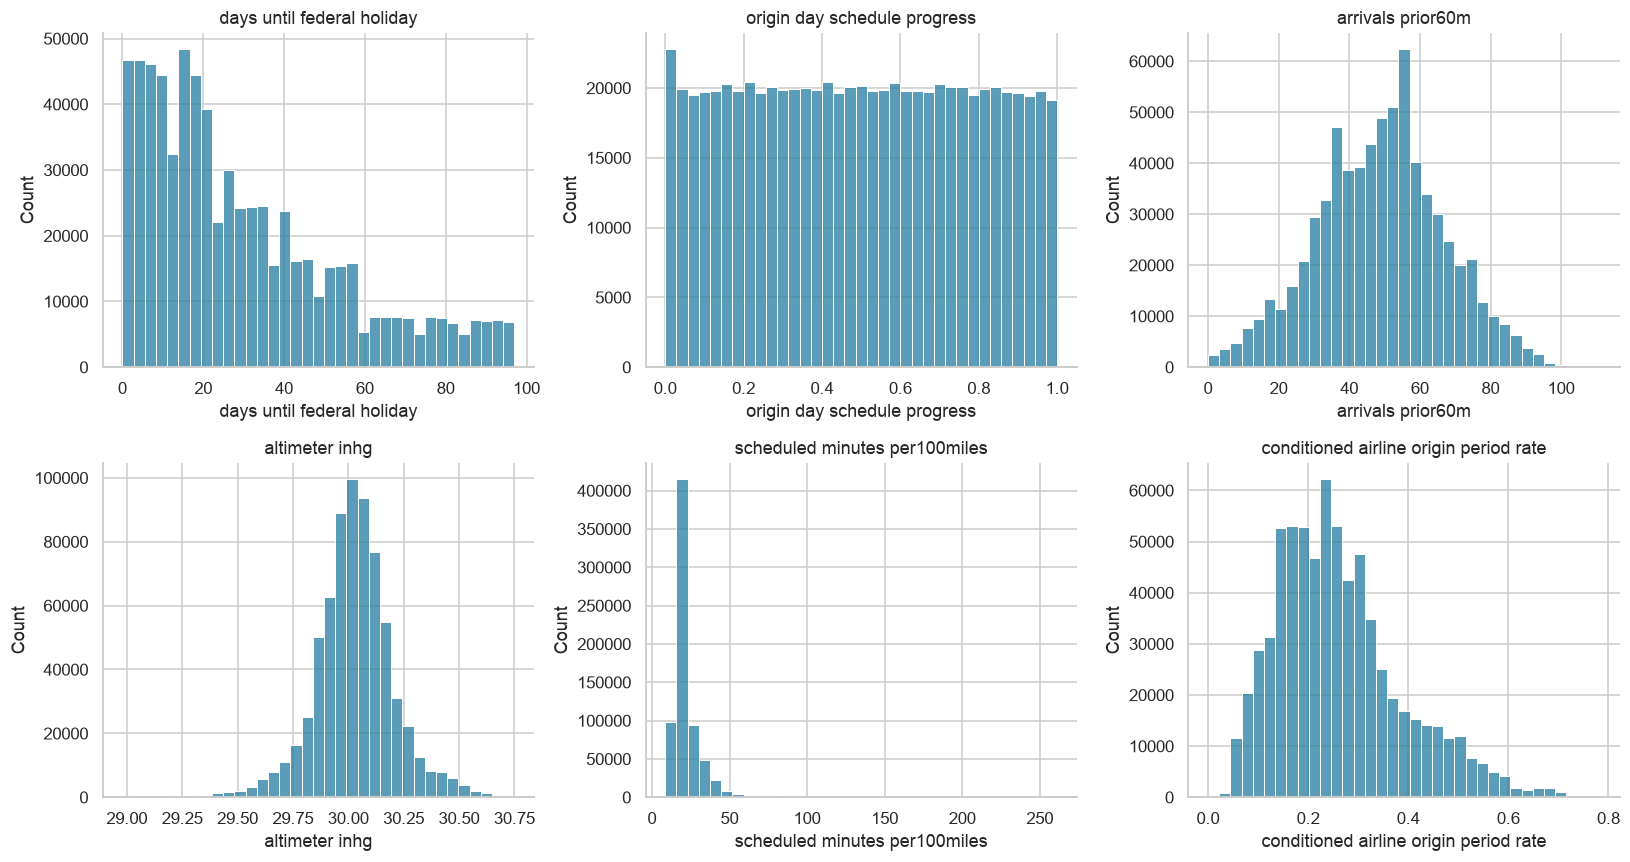

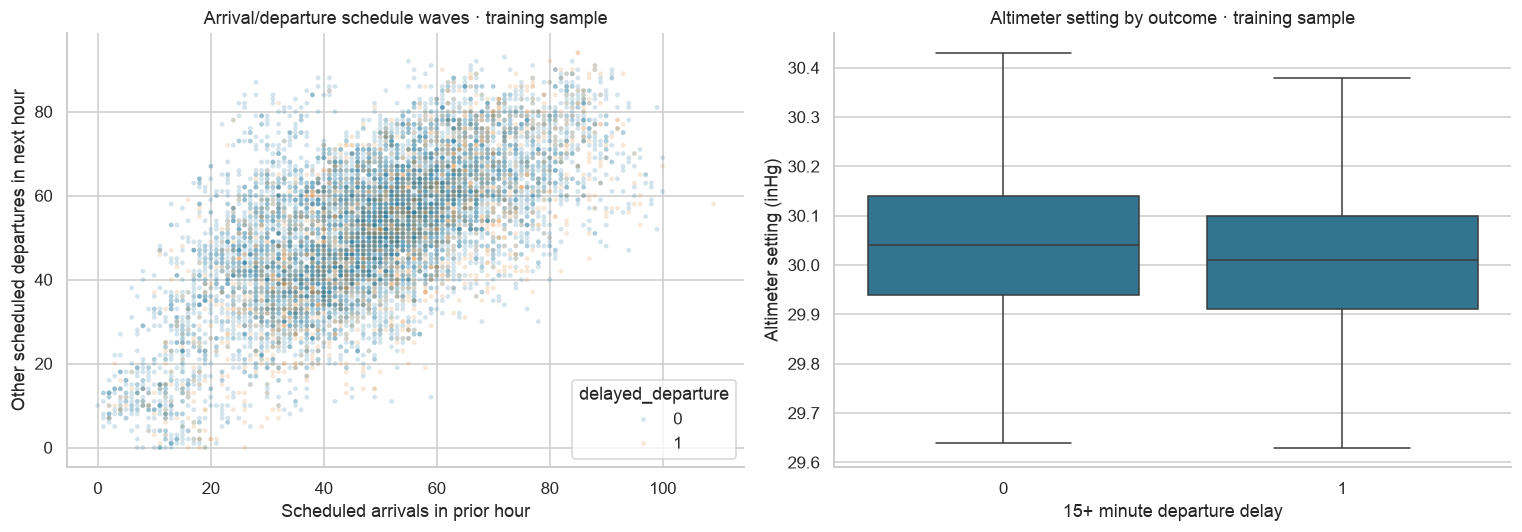

In [18]:
plot_columns = ['days_until_federal_holiday','origin_day_schedule_progress','arrivals_prior60m',
                'altimeter_inhg','scheduled_minutes_per100miles','conditioned_airline_origin_period_rate']
fig, axes = plt.subplots(2,3,figsize=(15,8))
for c, ax in zip(plot_columns,axes.flat):
    sns.histplot(broad_features.loc[train_mask,c],bins=35,ax=ax)
    ax.set(title=c.replace('_',' '),xlabel=c.replace('_',' '))
extension_plot()
fig, axes = plt.subplots(1,2,figsize=(14,5))
scatter = broad_features.loc[train_mask].sample(10_000,random_state=BROAD_SEED).join(development[['delayed_departure']])
sns.scatterplot(data=scatter,x='arrivals_prior60m',y='departures_next60m',hue='delayed_departure',alpha=.2,s=10,ax=axes[0])
axes[0].set(title='Arrival/departure schedule waves · training sample',xlabel='Scheduled arrivals in prior hour',ylabel='Other scheduled departures in next hour')
sns.boxplot(data=scatter,x='delayed_departure',y='altimeter_inhg',showfliers=False,ax=axes[1])
axes[1].set(title='Altimeter setting by outcome · training sample',xlabel='15+ minute departure delay',ylabel='Altimeter setting (inHg)')
extension_plot()


### Development experiment declared before model scoring

For each quarter, train on the earlier 2025 months. Use the quarter's **first month only to choose the F1 warning threshold**, then score the following two months. There is no refit between threshold selection and scoring. Training samples contain 20,000 flights and the quarter's combined calibration/scoring sample contains 5,000, using the original shared month/outcome proportional-sampling rules. No classes are balanced.

Keep model settings fixed at the previous improvement winners. First compare every group, the previous 28 candidates, and the combined package with Logistic Regression and Random Forest. Take the two highest mean-F1 packages across those models into an all-four-model comparison against the same baseline. This is an exploratory selection process on development data, not an independent final test. Average precision, precision, recall, false alarms and runtimes accompany F1. No candidate is removed for having weak correlation or substantial class overlap.


In [19]:
BROAD_PACKAGES = {'current_66':CURRENT_B, 'previous_28':CURRENT_B+NEW_FEATURES}
BROAD_PACKAGES.update({name:CURRENT_B+columns for name,columns in BROAD_GROUPS.items()})
BROAD_PACKAGES['all_candidates'] = CURRENT_B+NEW_FEATURES+BROAD_NEW
FOLDS_BROAD = [('May–Jun','2025-03-31','2025-04-01','2025-06-30'),
               ('Aug–Sep','2025-06-30','2025-07-01','2025-09-30'),
               ('Nov–Dec','2025-09-30','2025-10-01','2025-12-31')]

def fixed_sample(population,n):
    population = population.sort_values('flight_id')
    if len(population)==n:
        return population
    strata = population['month'].astype(str)+'|'+population['delayed_departure'].astype(str)
    selected,_ = train_test_split(population.index,train_size=n,random_state=BROAD_SEED,stratify=strata)
    return population.loc[selected].sort_values('flight_id')

broad_cohorts = {}
for name,end,start,stop in FOLDS_BROAD:
    fitting = broad_frame.loc[broad_frame['flight_date'].le(end)]
    validation = broad_frame.loc[broad_frame['flight_date'].between(start,stop)]
    if name=='Nov–Dec':
        fitting = fitting.loc[fitting['model_sample']]
        validation = validation.loc[validation['model_sample']]
    else:
        fitting,validation = fixed_sample(fitting,20000),fixed_sample(validation,5000)
    calibration = validation.loc[validation['flight_date'].dt.month.eq(pd.Timestamp(start).month)]
    scoring = validation.loc[~validation.index.isin(calibration.index)]
    assert len(fitting)==20000 and len(validation)==5000
    assert fitting['flight_date'].max()<calibration['flight_date'].min()<=calibration['flight_date'].max()<scoring['flight_date'].min()
    broad_cohorts[name] = {'train':fitting.index.to_list(),'calibrate':calibration.index.to_list(),'score':scoring.index.to_list()}

BROAD_SETTINGS = {c['model_id']:c for c in FROZEN['choices'] if c['feature_set']=='B'}
BROAD_REPORT = ROOT/'reports/broad_feature_experiments.json'
broad_protocol = {'started_at_utc':datetime.now(timezone.utc).isoformat(),
    'query_period':'2025 only','history_lag_days':7,'package_columns':BROAD_PACKAGES,
    'model_settings':{m:{'recipe':c['recipe'],'params':c['params']} for m,c in BROAD_SETTINGS.items()},
    'folds':FOLDS_BROAD,'train_rows':20000,'quarter_calibration_scoring_rows':5000,
    'threshold':'Max F1 on first validation month, score subsequent two months; no refit',
    'package_selection':'Top two non-baseline mean-F1 packages averaged over LR and RF',
    'correlation_filter':False,'class_balancing':False,'new_final_test':False,
    'arrival_clock_policy':'User-approved arrival clock, inferred date, discrepancies retained and flagged',
    'input_sha256':broad_inputs_before}
BROAD_REPORT.write_text(json.dumps({'status':'protocol_declared','protocol':broad_protocol},indent=2)+'\n')
extension_table(pd.DataFrame({'predictors':{k:len(v) for k,v in BROAD_PACKAGES.items()}}))


                         predictors
current_66                       66
previous_28                      94
calendar_holidays                77
categories_combinations          72
route_geometry                   74
schedule_structure               75
departure_waves                  71
scheduled_arrivals               70
pressure_wind                    72
nonlinear_weather                72
conditioned_history              75
all_candidates                  158


In [20]:
BINARY_BROAD = [c for c in PREP['feature_sets']['B']+TIME_FEATURES+FLIGHT_FEATURES+WEATHER_NEW+NEW_FEATURES
    if c.endswith('_no_history')] + ['precip_trace','no_ceiling_reported','cloud_coverage_missing',
    'rain_reported','frozen_precip_reported','fog_or_mist_reported','thunder_reported',
    'condition_codes_missing','ceiling_height_missing','weather_report_missing','freezing_wet',
    'traffic_reference_missing_or_zero'] + BROAD_BINARY
COVERED_BROAD = CONFIG['preprocessing']['explicit_missingness_covered_columns']

def broad_pipeline(model_id,columns):
    recipe = BROAD_SETTINGS[model_id]['recipe']
    params = BROAD_SETTINGS[model_id]['params'].copy()
    params.pop('drop_duration',None)
    categorical = [c for c in columns if c in ['airline','origin','destination','weekday'] or c.endswith('_cat')]
    numeric = [c for c in columns if c not in categorical]
    transforms = []
    if recipe=='original':
        for name,cols,indicators in [('numeric',[c for c in numeric if c not in COVERED_BROAD],True),
                                     ('explicit',[c for c in numeric if c in COVERED_BROAD],False)]:
            steps = [('imputer',SimpleImputer(strategy='median',add_indicator=indicators,keep_empty_features=True))]
            if model_id!='random_forest':
                steps.append(('scaler',StandardScaler()))
            if cols:
                transforms.append((name,Pipeline(steps),cols))
    else:
        continuous = [c for c in numeric if c not in BINARY_BROAD]
        flags = [c for c in numeric if c in BINARY_BROAD]
        steps = [('imputer',SimpleImputer(strategy='median',keep_empty_features=True))]
        if model_id!='random_forest':
            steps.append(('scaler',StandardScaler()))
        if continuous:
            transforms.append(('continuous',Pipeline(steps),continuous))
        if flags:
            transforms.append(('binary',SimpleImputer(strategy='constant',fill_value=0,keep_empty_features=True),flags))
        missing = [c for c in numeric if c not in COVERED_BROAD]
        if missing:
            transforms.append(('missing',MissingIndicator(features='all',error_on_new=False),missing))
    transforms.append(('category',Pipeline([
        ('imputer',SimpleImputer(strategy='constant',fill_value='Unknown',missing_values=pd.NA,keep_empty_features=True)),
        ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=True))]),categorical))
    estimators = {
        'logistic_regression':LogisticRegression(max_iter=3000,random_state=BROAD_SEED),
        'knn':KNeighborsClassifier(algorithm='brute',n_jobs=2),
        'svm':SVC(kernel='rbf',cache_size=512,random_state=BROAD_SEED),
        'random_forest':RandomForestClassifier(n_estimators=200,max_features='sqrt',class_weight='balanced',random_state=BROAD_SEED,n_jobs=2)}
    return Pipeline([('preprocess',ColumnTransformer(transforms,sparse_threshold=1.0)),
                     ('classifier',estimators[model_id].set_params(**params))])

def broad_scores(model,frame):
    return model.decision_function(frame) if isinstance(model.named_steps['classifier'],SVC) else model.predict_proba(frame)[:,1]

def calibration_threshold(y,scores):
    precision,recall,thresholds = precision_recall_curve(y,scores)
    f1 = np.divide(2*precision[:-1]*recall[:-1],precision[:-1]+recall[:-1],
        out=np.zeros(len(thresholds)),where=(precision[:-1]+recall[:-1])>0)
    return float(thresholds[np.flatnonzero(np.isclose(f1,f1.max(),rtol=0,atol=1e-12))[-1]])

broad_runs, broad_score_audit = [], []
def evaluate_broad(model_id,package):
    columns = BROAD_PACKAGES[package]
    for fold,cohort in broad_cohorts.items():
        if any(r['model_id']==model_id and r['package']==package and r['fold']==fold for r in broad_runs):
            continue
        train,calibration,score = [broad_frame.loc[cohort[role]] for role in ['train','calibrate','score']]
        model = broad_pipeline(model_id,columns)
        started = perf_counter()
        model.fit(train[columns],train['delayed_departure'])
        fit_seconds = perf_counter()-started
        classifier = model.named_steps['classifier']
        if isinstance(classifier,SVC):
            assert classifier.fit_status_==0
        if isinstance(classifier,LogisticRegression):
            assert classifier.n_iter_.max()<classifier.max_iter
        cal_scores, scores = broad_scores(model,calibration[columns]),broad_scores(model,score[columns])
        assert np.isfinite(cal_scores).all() and np.isfinite(scores).all()
        threshold = calibration_threshold(calibration['delayed_departure'],cal_scores)
        y = score['delayed_departure'].to_numpy()
        tn,fp,fn,tp = confusion_matrix(y,scores>=threshold,labels=[0,1]).ravel()
        broad_runs.append({'model_id':model_id,'package':package,'fold':fold,
            'train_rows':len(train),'calibration_rows':len(calibration),'score_rows':len(score),
            'predictors':len(columns),'threshold':threshold,'f1':float(2*tp/(2*tp+fp+fn)),
            'precision':float(tp/(tp+fp)) if tp+fp else None,'recall':float(tp/(tp+fn)),
            'average_precision':float(average_precision_score(y,scores)),
            'warn_all_f1':float(2*y.mean()/(1+y.mean())),
            'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn),'fit_seconds':fit_seconds})
        broad_score_audit.append({'model_id':model_id,'package':package,'fold':fold,
            'y_true':y.tolist(),'score':scores.tolist(),'threshold':threshold})
        print(f'{model_id} / {package} / {fold}: F1={broad_runs[-1]["f1"]:.3f}, AP={broad_runs[-1]["average_precision"]:.3f}',flush=True)
        BROAD_REPORT.write_text(json.dumps({'status':'development_screening_running','protocol':broad_protocol,
            'runs':broad_runs},indent=2,allow_nan=False)+'\n')


logistic_regression / current_66 / May–Jun: F1=0.500, AP=0.455


logistic_regression / current_66 / Aug–Sep: F1=0.435, AP=0.402


logistic_regression / current_66 / Nov–Dec: F1=0.481, AP=0.443


random_forest / current_66 / May–Jun: F1=0.478, AP=0.452


random_forest / current_66 / Aug–Sep: F1=0.444, AP=0.402


...

logistic_regression / all_candidates / Nov–Dec: F1=0.484, AP=0.451


random_forest / all_candidates / May–Jun: F1=0.495, AP=0.453


random_forest / all_candidates / Aug–Sep: F1=0.460, AP=0.389


random_forest / all_candidates / Nov–Dec: F1=0.477, AP=0.422


                                                   f1  average_precision  precision    recall  fit_seconds
model_id            package                                                                               
logistic_regression current_66               0.471847           0.433324   0.354072  0.714866     0.170107
random_forest       current_66               0.466274           0.428512   0.382031  0.618378     2.927172
logistic_regression previous_28              0.455393           0.434314   0.364192  0.636283     0.247006
random_forest       previous_28              0.471705           0.415350   0.368453  0.661419     4.328353
logistic_regression calendar_holidays        0.456559           0.435011   0.318766  0.855169     0.176080
random_forest       calendar_holidays        0.476722           0.428266   0.378079  0.654069     3.395374
logistic_regression categories_combinations  0.466925           0.427430   0.343565  0.731754     0.205941
random_forest       categories_combin

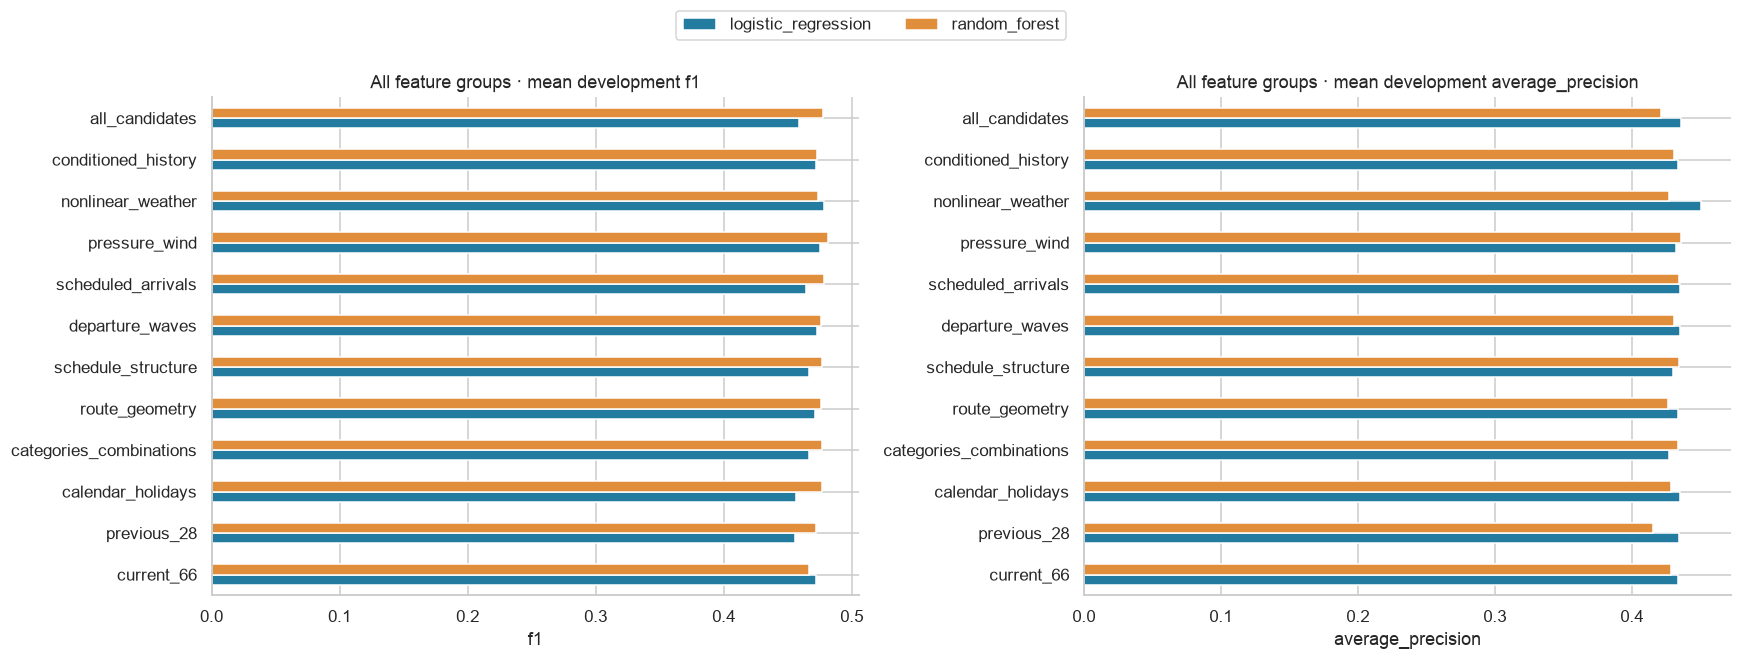

In [21]:
for package in BROAD_PACKAGES:
    for model_id in ['logistic_regression','random_forest']:
        evaluate_broad(model_id,package)
pilot_results = pd.DataFrame(broad_runs)
pilot_means = pilot_results.groupby(['model_id','package'],sort=False)[['f1','average_precision','precision','recall','fit_seconds']].mean()
package_ranking = pilot_means['f1'].groupby('package',sort=False).mean().drop('current_66').sort_values(ascending=False,kind='stable')
BROAD_FINALISTS = package_ranking.head(2).index.tolist()
extension_table(pilot_means)
print('Packages taken forward, based on development F1:',BROAD_FINALISTS)
fig,axes = plt.subplots(1,2,figsize=(16,6))
for metric,ax in zip(['f1','average_precision'],axes):
    pilot_means[metric].unstack('model_id').plot.barh(ax=ax)
    ax.set(title='All feature groups · mean development '+metric,xlabel=metric,ylabel='')
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(.5,1.01), title='')
plt.tight_layout(rect=[0,0,1,.93])
plt.show()


knn / current_66 / May–Jun: F1=0.493, AP=0.459


knn / current_66 / Aug–Sep: F1=0.447, AP=0.391


knn / current_66 / Nov–Dec: F1=0.467, AP=0.396


svm / current_66 / May–Jun: F1=0.463, AP=0.444


svm / current_66 / Aug–Sep: F1=0.427, AP=0.391


...

knn / nonlinear_weather / Nov–Dec: F1=0.461, AP=0.392


svm / nonlinear_weather / May–Jun: F1=0.460, AP=0.453


svm / nonlinear_weather / Aug–Sep: F1=0.411, AP=0.395


svm / nonlinear_weather / Nov–Dec: F1=0.439, AP=0.409


           model_id           package       f1  average_precision  precision   recall  fit_seconds  delta_f1  delta_average_precision
logistic_regression        current_66 0.471847           0.433324   0.354072 0.714866     0.170107  0.000000                 0.000000
      random_forest        current_66 0.466274           0.428512   0.382031 0.618378     2.927172  0.000000                 0.000000
logistic_regression     pressure_wind 0.475349           0.432395   0.364299 0.684957     0.172531  0.003502                -0.000928
      random_forest     pressure_wind 0.481618           0.436196   0.383752 0.651181     3.224197  0.015344                 0.007684
logistic_regression nonlinear_weather 0.478369           0.450157   0.355705 0.736401     0.206557  0.006522                 0.016834
      random_forest nonlinear_weather 0.473786           0.427475   0.381634 0.654183     3.318437  0.007512                -0.001037
                knn        current_66 0.468940           0.415

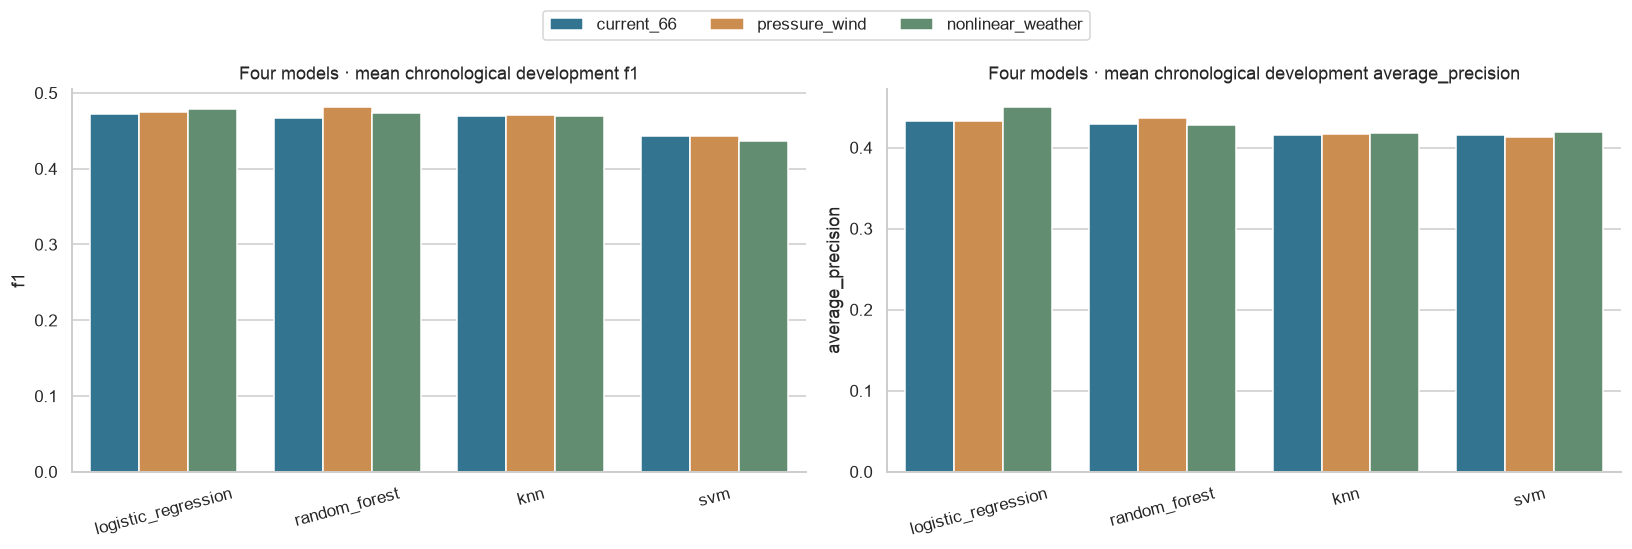

In [22]:
for package in ['current_66']+BROAD_FINALISTS:
    for model_id in ['logistic_regression','knn','svm','random_forest']:
        evaluate_broad(model_id,package)
all_runs = pd.DataFrame(broad_runs)
all_model_results = all_runs.loc[all_runs['package'].isin(['current_66']+BROAD_FINALISTS)]
all_model_means = all_model_results.groupby(['model_id','package'],sort=False)[['f1','average_precision','precision','recall','fit_seconds']].mean()
comparison = all_model_means.reset_index()
baseline_means = all_model_means.xs('current_66',level='package')
for metric in ['f1','average_precision']:
    comparison['delta_'+metric] = comparison[metric]-comparison['model_id'].map(baseline_means[metric])
extension_table(comparison,index=False)
fig,axes = plt.subplots(1,2,figsize=(15,5))
for metric,ax in zip(['f1','average_precision'],axes):
    sns.barplot(data=comparison,x='model_id',y=metric,hue='package',errorbar=None,ax=ax)
    ax.tick_params(axis='x',rotation=15)
    ax.set(title='Four models · mean chronological development '+metric,xlabel='',ylabel=metric)
    ax.legend(title='',fontsize=8)
handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    ax.get_legend().remove()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(.5,1.01), title='')
plt.tight_layout(rect=[0,0,1,.93])
plt.show()


### What this experiment can establish

Positive or negative changes below are **development findings** from matched flights and fixed model settings. Feature-package selection has already used these scoring periods, so do not present them as untouched-test performance. Results may differ by model; a combined package can make KNN worse even when one group helps a linear model.

No fitted model bundle is saved or promoted here. The notebook retains the candidate columns, package definitions, scores/metrics in memory and one compact JSON experiment report. Existing Tableau exports remain the previous frozen study; a future workbook should label any new development findings separately.


In [23]:
assert len(broad_frame)==len(development)==938417
assert broad_frame['flight_date'].dt.year.eq(2025).all()
for columns in BROAD_PACKAGES.values():
    assert len(columns)==len(set(columns))
    assert not {'delayed_departure','flight_id','flight_number','departure_outcome_event_utc',
        'Tail_Number','tail_number','DepDelay','ArrDelay','LateAircraftDelay'}.intersection(columns)
assert all(extension_sha(ROOT/p)==checksum for p,checksum in broad_inputs_before.items())
broad_summary = {'status':'executed_pending_independent_audit','protocol':broad_protocol,
    'development_rows':len(broad_frame),'new_columns':len(BROAD_NEW),'new_groups':BROAD_GROUPS,
    'retained_previous_candidates':len(NEW_FEATURES),'all_candidate_predictors':len(BROAD_PACKAGES['all_candidates']),
    'models_compared':['logistic_regression','knn','svm','random_forest'],
    'training_missing_pct':broad_profile['training_missing_pct'].to_dict(),
    'arrival_source_audit':arrival_audit,
    'arrival_clock_disagreement_context_flights':int((arrival_disagreement_audit>0).sum()),
    'finalist_packages':BROAD_FINALISTS,'runs':broad_runs,
    'all_model_comparison':json.loads(comparison.to_json(orient='records')),
    'original_artifacts_unchanged':True,'new_2026_outcome_access':False,
    'no_processed_datasets_or_fitted_model_bundles_written':True}
BROAD_REPORT.write_text(json.dumps(broad_summary,indent=2,allow_nan=False)+'\n')
print(f'Completed {len(broad_runs)} development fits. Detailed results: reports/broad_feature_experiments.json')
print('No correlation-based rejection. No claim of a new final-test F1 score.')


Completed 90 development fits. Detailed results: reports/broad_feature_experiments.json
No correlation-based rejection. No claim of a new final-test F1 score.


### Measured findings from the broader search

**Executed: 13 new code cells, four figures, 90 development fits, no notebook errors or warnings.** The original 57 cells and outputs remain intact. All 938,417 development flights are retained. There are 64 new candidates in nine groups; together with the previous 28 and current 66, the largest package contains 158 predictors. None was rejected for weak target correlation.

| Model | Current 66: mean F1 | Best added group among the two finalists: mean F1 | Change |
|---|---:|---:|---:|
| Logistic Regression | 0.4718 | 0.4784 · nonlinear weather | +0.0065 |
| KNN | 0.4689 | 0.4706 · pressure/wind | +0.0017 |
| SVM | 0.4432 | 0.4425 · pressure/wind | −0.0007 |
| Random Forest | 0.4663 | 0.4816 · pressure/wind | +0.0153 |

These are means over May–June, August–September and November–December 2025 scoring blocks. Thresholds came only from the preceding April, July and October calibration blocks. The same 20,000 fitting flights and 5,000 quarter-level calibration/scoring flights were used for every package/model. Model settings were held fixed, so this does not establish each package's best possible result after retuning.

**What the experiments suggest:**
- Nonlinear weather helps Logistic Regression more than a large combined feature list; its mean average precision rises from 0.4333 to 0.4502. Pressure/wind is the strongest screened group for Random Forest. Individual group components have not been isolated, so do not attribute that entire gain to pressure alone.
- KNN's improvement is tiny, and SVM gains no F1 from either finalist. SVM's nonlinear-weather AP rises slightly while its F1 falls, illustrating why ranking and warning decisions need separate assessment.
- The all-158 package is not the best pilot package: LR mean F1 is 0.4586 and RF 0.4772. Weak correlation did not prevent us from trying these features; additional variables also did not guarantee better predictions.
- The previous 28 candidates alone did not improve LR F1 in this screen. That is a useful negative finding, not a reason to suppress the comparison.

**Source/implementation checks:** 14 national schedule files supplied 1,108,714 incoming schedules. All were retained; 26 clock/duration disagreements were flagged, affecting the prior-hour context of 892 development flights. Repeated daylight-saving times were resolved against the published schedule. Independent checks verified all 90 score arrays and confusion matrices, plus sampled schedule counts/shares, arrival windows, conditioned histories and pressure parsing. Missing numeric/category values are handled explicitly for pandas' nullable types.

These are exploratory development gains, with package-selection optimism and no new untouched-test result. Existing fitted models, preparation datasets/manifest and Tableau exports are unchanged. No extra processed or split datasets were saved. The candidate columns and package definitions remain in memory; machine-readable outcomes are in [broad_feature_experiments.json](../reports/broad_feature_experiments.json), with [research notes](../reports/BROAD_FEATURE_RESEARCH.md) and [execution audit](../reports/broad_feature_notebook_audit.json).
